# Spatiotemporal Data Analytics and Dimensionality Reduction for Social Vulnerability Assessment in Region XI (2020–2024)
  
**Institution:** Department of Data Science, School of Arts and Sciences, Ateneo de Davao University  

---
### Notebook Workflow Overview
1. **Step 1 (`hmG-Uohi1sSj`):** Environment Setup & Harmonized PSA Region XI Panel Dataset ($N = 30$, 6 Spatial Units $\times$ 5 Years, 2020–2024)
2. **Step 2:** Descriptive Statistics (Pooled, 5-Year Provincial Means, and Annual Regional Trends) and Leave-One-Year-Out Validation
3. **Step 3:** Pooled Spatiotemporal $Z$-Score Standardization, Pearson Correlation Matrix ($|r| < 0.90$), KMO, & Bartlett's Test of Sphericity
4. **Step 4:** Pooled Principal Component Analysis (PCA), Kaiser Criterion ($\lambda > 1.0$), & Orthogonal Varimax Rotation
5. **Step 5:** Cardinality Alignment ($+1$), Composite $\text{SoVI}_{\text{Raw}}$, Min-Max Normalized $\text{SoVI}' \in [0, 1]$, & Vulnerability Tiers
6. **Step 6:** Global Moran's $I$ Spatial Autocorrelation (Queen Contiguity & Exact $6! = 720$ Permutation Inference)
7. **Step 7:** Sensitivity Analysis ($N-1$ Indicator Jackknife, $N=25$ Spatial Jackknife, $m=4$, Variance-Weighted) & Baselines 1 & 2 (Lloyd et al., 2022; Cutter et al., 2003)
8. **Step 8:** Publication-Grade Chapter 4 Visualizations (Figures 4.1–4.5) & Automated CSV/Excel Export

In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & HARMONIZED PSA REGION XI PANEL DATASET (2020-2024)
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats
import itertools
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import geopandas as gpd
import warnings
warnings.filterwarnings('ignore')

# Optional: Uncomment the two lines below in Google Colab if loading raw files from Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

units = [
    "Davao de Oro", "Davao del Norte", "Davao del Sur",
    "Davao Occidental", "Davao Oriental", "Davao City"
]
years = [2020, 2021, 2022, 2023, 2024]
cols = [
    "Poverty_Incidence", "Unemployment_Rate",
    "Highschool_Adults", "Functional_Literacy",
    "Female_Household_Head", "Age_Dependency_Under5", "Age_Dependency_Over80", "Average_Household_Size",
    "Poor_Roof_Materials", "Poor_Wall_Materials", "Insecure_Tenure", "Electricity_Access", "Water_Access",
    "Population_Density", "Urban_Population"
]

panel_data = {
    'Province': [
        'Davao de Oro', 'Davao de Oro', 'Davao de Oro', 'Davao de Oro', 'Davao de Oro',
        'Davao del Norte', 'Davao del Norte', 'Davao del Norte', 'Davao del Norte', 'Davao del Norte',
        'Davao del Sur', 'Davao del Sur', 'Davao del Sur', 'Davao del Sur', 'Davao del Sur',
        'Davao Occidental', 'Davao Occidental', 'Davao Occidental', 'Davao Occidental', 'Davao Occidental',
        'Davao Oriental', 'Davao Oriental', 'Davao Oriental', 'Davao Oriental', 'Davao Oriental',
        'Davao City', 'Davao City', 'Davao City', 'Davao City', 'Davao City'
        ],
'Year': [
    2020, 2021, 2022, 2023, 2024,
    2020, 2021, 2022, 2023, 2024,
    2020, 2021, 2022, 2023, 2024,
    2020, 2021, 2022, 2023, 2024,
    2020, 2021, 2022, 2023, 2024,
    2020, 2021, 2022, 2023, 2024
    ],
'Poverty_Incidence': [0.18, 0.177, 0.124, 0.071, 0.049499999999999995, 0.083, 0.073, 0.073, 0.073, 0.051, 0.075, 0.072, 0.08149999999999999, 0.091, 0.072, 0.3363333333333333, 0.345, 0.27149999999999996, 0.198, 0.1535, 0.2376666666666667, 0.218, 0.2545, 0.291, 0.206, 0.075, 0.072, 0.08149999999999999, 0.091, 0.072],
'Unemployment_Rate': [0.0627399, 0.02921, 0.03501, 0.02635, 0.024900000000000002, 0.0480435, 0.039670000000000004, 0.05143, 0.026099999999999998, 0.038650000000000004, 0.0784479, 0.032490000000000005, 0.03355, 0.019880000000000002, 0.0096, 0.036434, 0.04037, 0.0191, 0.02021, 0.027540000000000002, 0.0934803, 0.055330000000000004, 0.038849999999999996, 0.03828, 0.025019999999999997, 0.1438476, 0.06328, 0.04232, 0.04136, 0.04283000000000001],
'Highschool_Adults': [0.361352390841377, 0.5509381939681225, 0.5738550669390696, 0.5967719399100168, 0.5616146745185421, 0.4489328474752733, 0.6524402596328758, 0.6502230736877559, 0.6480058877426361, 0.6602495282327291, 0.39726814707695446, 0.571037164640783, 0.5868839590538635, 0.602730753466944, 0.6382601160532736, 0.20301869215883067, 0.5379568133486013, 0.5415009400468155, 0.5450450667450296, 0.3797035557155134, 0.3254073509992328, 0.38342561535046615, 0.4011417796874611, 0.41885794402445614, 0.5443559860516137, 0.5138050895631138, 0.6903275324128765, 0.6735024987595217, 0.656677465106167, 0.7034440643496234],
'Functional_Literacy': [0.8712978446657602, 0.8146790441605893, 0.7580602436554185, 0.7014414431502476, 0.6588140218232968, 0.9198823807572347, 0.8615211931862203, 0.803160005615206, 0.7447988180441916, 0.6902530505852448, 0.8743420119608994, 0.8144206994542394, 0.7544993869475795, 0.6945780744409195, 0.6458538729030532, 0.1201952333056921, 0.11023864848193596, 0.10028206365817982, 0.09032547883442368, 0.08036889401066757, 0.8582683926301601, 0.8082195333246833, 0.7581706740192066, 0.7081218147137298, 0.6763788297135063, 0.8844595038364448, 0.8346556832053301, 0.7848518625742155, 0.7350480419431008, 0.6964413322807798],
'Female_Household_Head': [0.15336812797086566, 0.15695263173643736, 0.16572542857608574, 0.17449822541573415, 0.20187276647717847, 0.1676685501831367, 0.20208267753379672, 0.2032092230439758, 0.20433576855415486, 0.21832073817377146, 0.1916674421532617, 0.2091941350424004, 0.22768181862842546, 0.24616950221445055, 0.2569453992172391, 0.13919549785764532, 0.1693715711358053, 0.1883010316585656, 0.20723049218132586, 0.2019060776714943, 0.16310400959561344, 0.18586716771505596, 0.17903208193646614, 0.17219699615787634, 0.2000496069602381, 0.2245117347431542, 0.2642073348640729, 0.26525043778943624, 0.26629354071479966, 0.328971679848515],
'Age_Dependency_Under5': [0.10258915740664741, 0.09565418983100546, 0.08871922225536351, 0.08178425467972156, 0.07484928710407962, 0.10485513178443404, 0.09759813032252343, 0.09034112886061282, 0.08308412739870222, 0.07582712593679164, 0.10358702153329777, 0.09595678192226464, 0.08832654231123152, 0.0806963027001984, 0.07306606308916525, 0.1201952333056921, 0.11023864848193596, 0.10028206365817982, 0.09032547883442368, 0.08036889401066757, 0.10295778728986038, 0.09627672953122464, 0.0895956717725889, 0.08291461401395316, 0.07623355625531741, 0.09978170448335884, 0.0928558592374712, 0.08593001399158355, 0.07900416874569591, 0.07207832349980826],
'Age_Dependency_Over80': [0.007841865058426389, 0.010299120716565477, 0.012756376374704566, 0.015213632032843654, 0.017670887690982743, 0.0071516376503590485, 0.009438711781357143, 0.011725785912355237, 0.014012860043353332, 0.016299934174351424, 0.008527791371103675, 0.01083687488571059, 0.013145958400317504, 0.015455041914924418, 0.017764125429531333, 0.007671231149045116, 0.009863965619606618, 0.012056700090168121, 0.014249434560729624, 0.01644216903129113, 0.009119569423069249, 0.011743988963743207, 0.014368408504417165, 0.016992828045091123, 0.01961724758576508, 0.006519039094537885, 0.008761212913375237, 0.01100338673221259, 0.013245560551049942, 0.015487734369887292],
'Average_Household_Size': [4.056251918821923, 3.97053888758592, 3.886637066272451, 3.8045081820385622, 3.7383872077686235, 4.105085494469088, 3.9999589046113493, 3.8975244876474537, 3.7977133000788994, 3.7184886097075385, 3.7193632616418784, 3.635231875890874, 3.553003528259695, 3.4726351723388107, 3.411551821163138, 4.053296668158854, 3.9301541351169575, 3.810752774924089, 3.6949789276291294, 3.6022433132010354, 4.105151930546036, 3.974931634854544, 3.8488420816293174, 3.7267522388124736, 3.637119079369783, 3.718391359668093, 3.6269491171437145, 3.537755611481352, 3.4507555420088547, 3.3867085651663866],
'Poor_Roof_Materials': [0.042480598324388434, 0.012924634480134848, 0.018992199327037797, 0.02505976417394075, 0.0311273290208437, 0.06126173195673326, 0.0515666360330215, 0.054862762726161564, 0.058158889419301626, 0.06145501611244169, 0.06045918367346939, 0.029757580098850833, 0.025631184232131846, 0.02150478836541286, 0.01737839249869387, 0.34294165939092247, 0.09631487399377048, 0.11476546504690598, 0.13321605610004147, 0.151666647153177, 0.1523956286105652, 0.18616837977541442, 0.16435324973232196, 0.1425381196892295, 0.12072298964613702, 0.036762563526572735, 0.005043379581884472, 0.015244170497501805, 0.025444961413119138, 0.03564575232873647],
'Poor_Wall_Materials': [0.41926032634891064, 0.37871926700519415, 0.3719910975924527, 0.36526292817971123, 0.3585347587669698, 0.3835550053193705, 0.37938984062649733, 0.355445212767222, 0.3315005849079467, 0.30755595704867134, 0.4628798185941043, 0.4264451562068295, 0.3880095384846537, 0.3495739207624779, 0.3111383030403021, 0.724937776098203, 0.5830907254470917, 0.5931816897211644, 0.603272653995237, 0.6133636182693095, 0.5478009052468584, 0.4734571147337621, 0.4735917257806856, 0.47372633682760906, 0.47386094787453253, 0.3091378179108793, 0.2784785134010896, 0.31440559410660535, 0.3503326748121211, 0.38625975551763686],
'Insecure_Tenure': [0.09212281630492324, 0.05134979471706887, 0.048271405739343576, 0.045193016761618285, 0.042114627783893, 0.14574690133223386, 0.07922331927327568, 0.09997369609178457, 0.12072407291029345, 0.14147444972880235, 0.10389889547829538, 0.03890077054531686, 0.056793631389046945, 0.07468649223277703, 0.0925793530765071, 0.05988590724207618, 0.038678628720812784, 0.051258661902825485, 0.06383869508483818, 0.07641872826685088, 0.11294525878379826, 0.05226999986516187, 0.08627254869028547, 0.12027509751540907, 0.1542776463405327, 0.2263960712980428, 0.13561917979427765, 0.1447267015678946, 0.15383422334151156, 0.16294174511512854],
'Electricity_Access': [0.8441348057640793, 0.8925659573793533, 0.8862995360214317, 0.8800331146635102, 0.8737666933055886, 0.8972614590580951, 0.9466621108937955, 0.9438513895116425, 0.9410406681294895, 0.9382299467473364, 0.9180028772854301, 0.9557166685427176, 0.9583345967172866, 0.9609525248918556, 0.9635704530664246, 0.5794172571691694, 0.6700968451072425, 0.6731852777546584, 0.6762737104020743, 0.6793621430494902, 0.8716817318539463, 0.9445545622480213, 0.9379212612447949, 0.9312879602415686, 0.9246546592383423, 0.9454777680210745, 0.9753965119979144, 0.9758884603618041, 0.9763804087256938, 0.9768723570895833],
'Water_Access': [0.9530371531123275, 0.9626052174096834, 0.9676615089028563, 0.9727178003960292, 0.9777740918892022, 0.9735606922371807, 0.9829943995412808, 0.9878215687775304, 0.99264873801378, 0.9974759072500294, 0.969860159518468, 0.9534756403303214, 0.9678319223207755, 0.9821882043112297, 0.9965444863016838, 0.8950269883093295, 0.8654268908561583, 0.8837462479455443, 0.9020656050349304, 0.9203849621243165, 0.9525625098173613, 0.9927524506829551, 0.993285779912934, 0.9938191091429128, 0.9943524383728917, 0.977730208013848, 0.9929707058431128, 0.9945877910593657, 0.9962048762756186, 0.9978219614918714],
'Population_Density': [146.0, 146.75248104742232, 147.52816620495585, 148.3079513781029, 149.0, 306.0, 307.2555269391541, 308.5441596074211, 309.83819681363167, 311.0, 306.0, 309.14407661034346, 311.9434873214036, 314.7682477024789, 317.0, 155.0, 154.6837519745695, 154.73727888624222, 154.790824320418, 155.0, 101.0, 101.24365663952948, 101.84526750853668, 102.45045327447791, 103.0, 635.0, 641.1583688748866, 647.6529447240322, 654.2133069958589, 660.0],
'Urban_Population': [0.5320286575284641, 0.525738267297733, 0.5195366136354691, 0.5134221608248654, 0.5072578227169787, 0.6828969554431464, 0.6829779456183994, 0.6830708602706843, 0.683175605342346, 0.6832169073134656, 0.5184274064962872, 0.5242338449529086, 0.5301480112458006, 0.5361713139895654, 0.541044262822831, 0.3226394332180389, 0.3241282036128677, 0.32562388267597964, 0.32712650261890874, 0.3285883412364058, 0.4181277468451946, 0.41930367806764, 0.4204975892525989, 0.4217094427127164, 0.4227495669799777, 0.9183071658218666, 0.9183281581616409, 0.9184415076799236, 0.9186454232006412, 0.9183886828557011]
}

df = pd.DataFrame(panel_data)
N, p = len(df), len(cols)
print(f"Loaded Balanced Region XI Spatiotemporal Panel: N = {N} observations ({len(units)} units x {len(years)} years), p = {p} indicators.")
print(df.head(10).to_string(index=False))

Loaded Balanced Region XI Spatiotemporal Panel: N = 30 observations (6 units x 5 years), p = 15 indicators.
       Province  Year  Poverty_Incidence  Unemployment_Rate  Highschool_Adults  Functional_Literacy  Female_Household_Head  Age_Dependency_Under5  Age_Dependency_Over80  Average_Household_Size  Poor_Roof_Materials  Poor_Wall_Materials  Insecure_Tenure  Electricity_Access  Water_Access  Population_Density  Urban_Population
   Davao de Oro  2020             0.1800           0.062740           0.361352             0.871298               0.153368               0.102589               0.007842                4.056252             0.042481             0.419260         0.092123            0.844135      0.953037          146.000000          0.532029
   Davao de Oro  2021             0.1770           0.029210           0.550938             0.814679               0.156953               0.095654               0.010299                3.970539             0.012925             0.378719         0

### Step 1: Descriptive Spatiotemporal Profile of the 15 PSA Indicators
Computes the pooled summary statistics ($N = 30$), 5-year provincial means, and annual regional means from 2020 to 2024.

In [2]:
# ==============================================================================
# CELL 2: DESCRIPTIVE STATISTICS & LOYO INTERPOLATION VALIDATION
# ==============================================================================

# Ensure df is instantiated from the panel_data dictionary in Cell 1
if 'df' not in locals() and 'panel_data' in locals():
    df = pd.DataFrame(panel_data)

# 1. Descriptive Statistics & Regional Profiles
# ==============================================================================
desc_rows = []
for c in cols:
    s = df[c]
    desc_rows.append({
        "Indicator": c,
        "Mean": s.mean(),
        "SD": s.std(ddof=1),
        "Median": s.median(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Min": s.min(),
        "Max": s.max(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurt()
    })
df_desc = pd.DataFrame(desc_rows)
print("=== TABLE 4.1: POOLED DESCRIPTIVE STATISTICS (N = 30) ===")
print(df_desc.round(2).to_string(index=False))

prov_means = df.groupby("Province")[cols].mean().loc[units]
print("\n=== TABLE 4.2: 5-YEAR PROVINCIAL MEANS OF INDICATORS (2020-2024) ===")
print(prov_means.round(2).to_string())

# 2. Leave-One-Year-Out (LOYO) Interpolation Validation Loop
# ==============================================================================
print("\n=== TABLE 4.3: LEAVE-ONE-YEAR-OUT (LOYO) INTERPOLATION VALIDATION ===")

# Hardcoded true empirical poverty rates for external validation bounds (2018 and 2025)
poverty_external_anchors = {
    'Davao de Oro': {2018: 0.186, 2025: 0.028},
    'Davao del Norte': {2018: 0.103, 2025: 0.029},
    'Davao del Sur': {2018: 0.081, 2025: 0.053},
    'Davao City': {2018: 0.081, 2025: 0.053},
    'Davao Occidental': {2018: 0.319, 2025: 0.109},
    'Davao Oriental': {2018: 0.277, 2025: 0.121}
}

# FLEMMS 2019 external anchor values manually retrieved from official PSA microdata summaries
flemms_2019_external_anchors = {
    'Davao de Oro': {'Functional_Literacy': 0.941908024, 'Highschool_Adults': 0.403869588},
    'Davao del Norte': {'Functional_Literacy': 0.982058988, 'Highschool_Adults': 0.567451113},
    'Davao del Sur': {'Functional_Literacy': 0.945460435, 'Highschool_Adults': 0.526374396},
    'Davao Occidental': {'Functional_Literacy': 0.834203311, 'Highschool_Adults': 0.240230701},
    'Davao Oriental': {'Functional_Literacy': 0.926623126, 'Highschool_Adults': 0.371837129},
    'Davao City': {'Functional_Literacy': 0.945460435, 'Highschool_Adults': 0.526374396}
}

validation_metrics = []

for col in cols:
    if col == 'Unemployment_Rate':
        continue  # Systematically exclude unemployment rate from cross-validation
        
    # Assign specific empirical anchor timelines based on data source availability
    if col == 'Poverty_Incidence':
        base_anchors = [2018, 2021, 2023, 2025]
    elif col in ['Population_Density', 'Average_Household_Size', 'Urban_Population', 'Age_Dependency_Under5', 'Age_Dependency_Over80']:
        base_anchors = [2020, 2024]
    elif col in ['Highschool_Adults', 'Functional_Literacy']:
        base_anchors = [2019, 2020, 2024]
    else:
        base_anchors = [2020, 2021, 2024]
        
    panel_years = [2020, 2021, 2022, 2023, 2024]
    check_years = [y for y in panel_years if y not in base_anchors]
    
    # Configure configurations to test: [Exclude Davao Occidental?, Label Suffix]
    eval_modes = [(False, ""), (True, " (Excl. Davao Occidental)")] if col in ['Highschool_Adults', 'Functional_Literacy'] else [(False, "")]

    for exclude_outlier, suffix in eval_modes:
        errors_sq = []
        errors_abs_pct = []
        
        target_provinces = df['Province'].unique()
        if exclude_outlier:
            target_provinces = [p for p in target_provinces if p != 'Davao Occidental']
            
        for prov in target_provinces:
            prov_data = df[df['Province'] == prov]
            
            def get_value(year):
                if col == 'Poverty_Incidence' and year in base_anchors:
                    return poverty_external_anchors.get(prov, {}).get(year, None)
                if col in ['Functional_Literacy', 'Highschool_Adults'] and year == 2019:
                    return flemms_2019_external_anchors.get(prov, {}).get(col, None)
                row = prov_data[prov_data['Year'] == year]
                return float(row[col].iloc[0]) if not row.empty else None

            for dropped_year in check_years:
                y_true = get_value(dropped_year)
                if y_true is None:
                    continue
                    
                lower_bounds = [y for y in base_anchors if y < dropped_year and get_value(y) is not None]
                upper_bounds = [y for y in base_anchors if y > dropped_year and get_value(y) is not None]
                
                if lower_bounds and upper_bounds:
                    year_a = max(lower_bounds)
                    year_b = min(upper_bounds)
                    
                    x_a = get_value(year_a)
                    x_b = get_value(year_b)
                    
                    if x_a is not None and x_b is not None:
                        y_pred = x_a + (x_b - x_a) * (dropped_year - year_a) / (year_b - year_a)
                        res = y_true - y_pred
                        errors_sq.append(res ** 2)
                        if y_true != 0:
                            errors_abs_pct.append(abs(res) / abs(y_true))

        if errors_sq:
            rmse = np.sqrt(np.mean(errors_sq))
            mape = np.mean(errors_abs_pct) * 100 if errors_abs_pct else 0.0
            validation_metrics.append({
                "Indicator": f"{col}{suffix}",
                "Validation Anchors": str(base_anchors),
                "RMSE": round(rmse, 4),
                "MAPE (%)": round(mape, 2)
            })
        else:
            validation_metrics.append({
                "Indicator": f"{col}{suffix}",
                "Validation Anchors": str(base_anchors),
                "RMSE": "N/A",
                "MAPE (%)": "N/A"
            })

df_val = pd.DataFrame(validation_metrics)
print(df_val.to_string(index=False))


=== TABLE 4.1: POOLED DESCRIPTIVE STATISTICS (N = 30) ===
             Indicator   Mean     SD  Median    IQR    Min    Max  Skewness  Kurtosis
     Poverty_Incidence   0.14   0.09    0.09   0.13   0.05   0.34      0.95     -0.37
     Unemployment_Rate   0.04   0.03    0.04   0.02   0.01   0.14      2.33      7.16
     Highschool_Adults   0.53   0.13    0.56   0.22   0.20   0.70     -0.79      0.03
   Functional_Literacy   0.66   0.27    0.75   0.13   0.08   0.92     -1.58      1.08
 Female_Household_Head   0.20   0.04    0.20   0.05   0.14   0.33      1.02      1.31
 Age_Dependency_Under5   0.09   0.01    0.09   0.02   0.07   0.12      0.40     -0.27
 Age_Dependency_Over80   0.01   0.00    0.01   0.01   0.01   0.02      0.11     -0.97
Average_Household_Size   3.76   0.21    3.73   0.29   3.39   4.11     -0.04     -0.88
   Poor_Roof_Materials   0.08   0.07    0.05   0.09   0.01   0.34      1.91      4.79
   Poor_Wall_Materials   0.43   0.11    0.38   0.12   0.28   0.72      1.01      0

### Step 2: Pooled $Z$-Score Standardization, Multicollinearity ($|r| < 0.90$), KMO, & Bartlett's Test
Standardizes each indicator across the full $N = 30$ spatiotemporal panel and runs formal psychometric factorability diagnostics.

In [3]:
# ==============================================================================
# CELL 3: POOLED Z-SCORES, CORRELATION MATRIX, KMO & BARTLETT'S TEST
# ==============================================================================
Z = (df[cols] - df[cols].mean()) / df[cols].std(ddof=1)
R = Z.corr().values
corr_df = pd.DataFrame(R, index=cols, columns=cols)

off = R - np.eye(p)
max_r = np.max(np.abs(off))
invR = np.linalg.inv(R)
partial_R = np.zeros_like(R)
for i in range(p):
    for j in range(p):
        if i != j:
            partial_R[i, j] = -invR[i, j] / np.sqrt(invR[i, i] * invR[j, j])

kmo_overall = np.sum(off**2) / (np.sum(off**2) + np.sum(partial_R**2))
kmo_vars = np.sum(off**2, axis=1) / (np.sum(off**2, axis=1) + np.sum(partial_R**2, axis=1))
detR = np.linalg.det(R)
bartlett_chi2 = -(N - 1 - (2*p + 5)/6.0) * np.log(detR)
bartlett_df = int(p*(p-1)/2)
bartlett_p = stats.chi2.sf(bartlett_chi2, bartlett_df)

print("=== BIVARIATE PEARSON CORRELATION MATRIX (N = 30) ===")
print(corr_df.round(3).to_string())
print(f"\nMax Pairwise |r| = {max_r:.4f} (Threshold < 0.90 -> All indicators Retained)")
print(f"Overall KMO Measure of Sampling Adequacy = {kmo_overall:.4f}")
print(f"Bartlett's Test of Sphericity: Chi2 = {bartlett_chi2:.2f}, df = {bartlett_df}, p = {bartlett_p:.4e}")

=== BIVARIATE PEARSON CORRELATION MATRIX (N = 30) ===
                        Poverty_Incidence  Unemployment_Rate  Highschool_Adults  Functional_Literacy  Female_Household_Head  Age_Dependency_Under5  Age_Dependency_Over80  Average_Household_Size  Poor_Roof_Materials  Poor_Wall_Materials  Insecure_Tenure  Electricity_Access  Water_Access  Population_Density  Urban_Population
Poverty_Incidence                   1.000             -0.063             -0.652               -0.561                 -0.569                  0.500                 -0.097                   0.440                0.764                0.812           -0.302              -0.660        -0.622              -0.585            -0.688
Unemployment_Rate                  -0.063              1.000             -0.265                0.412                 -0.038                  0.417                 -0.633                   0.251               -0.011               -0.126            0.559               0.191         0.119          

### Step 3: Pooled Principal Component Analysis (PCA) & Orthogonal Varimax Rotation
Extracts principal components satisfying the Kaiser criterion ($\lambda_k > 1.0$) and applies Kaiser-normalized orthogonal Varimax rotation and cardinality alignment.

In [4]:
# ====================================================================================================
# CELL 4: PCA EXTRACTION & ORTHOGONAL VARIMAX ROTATION (FULLY DYNAMIC ENGINE)
# ====================================================================================================

def varimax(Phi, gamma=1.0, q=100, tol=1e-8):
    """
    Kaiser-normalized orthogonal Varimax rotation matching specified
    iteration maximums, gamma coefficients, and convergence limits.
    """
    h = np.sqrt(np.sum(Phi**2, axis=1, keepdims=True))
    Phi_norm = Phi / h
    p_rows, k_cols = Phi_norm.shape
    R_rot = np.eye(k_cols)
    d = 0
    for _ in range(q):
        d_old = d
        Lambda = np.dot(Phi_norm, R_rot)
        u, s, vh = np.linalg.svd(
            np.dot(Phi_norm.T, Lambda**3 - (gamma / p_rows) * np.dot(Lambda, np.diag(np.diag(np.dot(Lambda.T, Lambda)))))
        )
        R_rot = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and abs(d - d_old) < tol:
            break

    L_rotated = np.dot(Phi_norm, R_rot) * h
    return L_rotated, R_rot

# Extract variable dimensions and components directly from Cell 3 structures
p = len(cols)

# Extract eigenvalues and eigenvectors from the correlation matrix R computed in Cell 3
eigvals, eigvecs = np.linalg.eigh(R)
idx_s = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[idx_s], eigvecs[:, idx_s]
var_exp = eigvals / p * 100
cum_var = np.cumsum(var_exp)

print("=== EIGENVALUES & EXPLAINED VARIANCE (UNROTATED) ===")
for i in range(p):
    status = "RETAINED (lambda > 1)" if eigvals[i] > 1.0 else "Excluded"
    print(f"PC{i+1:2d}: Eigenvalue = {eigvals[i]:.4f} | % Variance = {var_exp[i]:6.2f}% | Cum. % = {cum_var[i]:6.2f}% | {status}")

# Retain components matching Kaiser Criterion (Eigenvalue > 1.0)
m = int(np.sum(eigvals > 1.0))
rc_labels = [f"RC{i+1}" for i in range(m)]

# Calculate unrotated structural factor loading matrix
load_unrot = eigvecs[:, :m] * np.sqrt(eigvals[:m])
communalities = np.sum(load_unrot**2, axis=1)

# Apply custom configured strict Varimax rotation loops
load_rot, R_rot_matrix = varimax(load_unrot, q=100, gamma=1.0, tol=1e-8)

# Sort rotated dimensions chronologically by variance footprint
rot_ss = np.sum(load_rot**2, axis=0)
ord_r = np.argsort(rot_ss)[::-1]
load_rot = load_rot[:, ord_r]
rot_ss = rot_ss[ord_r]
rot_var = rot_ss / p * 100
rot_cum = np.cumsum(rot_var)

# Define explicit directional configuration properties matching Cell 3 parameters
cardinality_rules = {
    'Poverty_Incidence': 1,       # More poverty = More vulnerable
    'Unemployment_Rate': 1,       # More unemployment = More vulnerable
    'Highschool_Adults': -1,      # More educated adults = Less vulnerable
    'Functional_Literacy': -1,    # More literate adults = Less vulnerable
    'Female_Household_Head': 1,   # More female-led households = More vulnerable
    'Age_Dependency_Under5': 1,   # More infants = More vulnerable
    'Age_Dependency_Over80': 1,   # More extreme elderly = More vulnerable
    'Average_Household_Size': 1,  # Larger households = More vulnerable
    'Poor_Roof_Materials': 1,     # Worse roofs = More vulnerable
    'Poor_Wall_Materials': 1,     # Worse walls = More vulnerable
    'Insecure_Tenure': 1,         # More insecure tenure = More vulnerable
    'Electricity_Access': -1,     # More electricity grid = Less vulnerable
    'Water_Access': -1,           # More clean water access = Less vulnerable
    'Population_Density': 1,      # Higher density congestion = More vulnerable
    'Urban_Population': -1         # More urban population = Less vulnerable
}

# Evaluate dominant anchors and execute sign alignments directly on the structural loadings
for comp_idx in range(m):
    dominant_var_idx = np.argmax(np.abs(load_rot[:, comp_idx]))
    dominant_var_name = cols[dominant_var_idx]

    target_sign = cardinality_rules.get(dominant_var_name, 1)
    current_sign = np.sign(load_rot[dominant_var_idx, comp_idx])

    if current_sign != target_sign:
        load_rot[:, comp_idx] *= -1

# Map variables perfectly into the target DataFrame using variables initialized in Cell 3
load_table = pd.DataFrame(load_rot, index=cols, columns=rc_labels)
load_table["Communality_h2"] = communalities
load_table["KMO_MSA"] = kmo_vars  # Directly references Cell 3 MSA array

print("\n=== VARIMAX-ROTATED COMPONENT LOADINGS, COMMUNALITIES & KMO (SIGN-ALIGNED) ===")
print(load_table.round(4).to_string())

print("\nRotated Eigenvalues & Summary Metrics:")
ev_str = " | ".join([f"{rc_labels[i]} = {rot_ss[i]:.4f} ({rot_var[i]:.2f}%)" for i in range(m)])
print(f"  {ev_str} | Total Retained Variance Explained = {rot_cum[m-1]:.2f}%")


=== EIGENVALUES & EXPLAINED VARIANCE (UNROTATED) ===
PC 1: Eigenvalue = 7.6473 | % Variance =  50.98% | Cum. % =  50.98% | RETAINED (lambda > 1)
PC 2: Eigenvalue = 3.0762 | % Variance =  20.51% | Cum. % =  71.49% | RETAINED (lambda > 1)
PC 3: Eigenvalue = 1.7103 | % Variance =  11.40% | Cum. % =  82.89% | RETAINED (lambda > 1)
PC 4: Eigenvalue = 1.1926 | % Variance =   7.95% | Cum. % =  90.84% | RETAINED (lambda > 1)
PC 5: Eigenvalue = 0.3765 | % Variance =   2.51% | Cum. % =  93.35% | Excluded
PC 6: Eigenvalue = 0.3733 | % Variance =   2.49% | Cum. % =  95.84% | Excluded
PC 7: Eigenvalue = 0.2768 | % Variance =   1.85% | Cum. % =  97.69% | Excluded
PC 8: Eigenvalue = 0.1387 | % Variance =   0.92% | Cum. % =  98.61% | Excluded
PC 9: Eigenvalue = 0.0868 | % Variance =   0.58% | Cum. % =  99.19% | Excluded
PC10: Eigenvalue = 0.0660 | % Variance =   0.44% | Cum. % =  99.63% | Excluded
PC11: Eigenvalue = 0.0344 | % Variance =   0.23% | Cum. % =  99.86% | Excluded
PC12: Eigenvalue = 0.0094 

### Step 4: Composite $\text{SoVI}_{\text{Raw}}$, Min-Max Rescaled $\text{SoVI}' \in [0, 1]$, & Provincial Rankings
Computes regression component scores $\mathbf{F} = \mathbf{Z}\mathbf{R}^{-1}\mathbf{L}_{\text{rot}}$, aggregates $\text{SoVI}_{\text{Raw}} = \text{RC1} + \text{RC2} + \text{RC3} + \text{RC4}$, normalizes to $[0, 1]$, and classifies observations into five equal-interval vulnerability tiers.

In [5]:
# ==============================================================================
# CELL 5: COMPOSITE SoVI SCORES, TIERS & 5-YEAR PROVINCIAL SUMMARY (HOUSING-ADJUSTED)
# ==============================================================================
def classify_tier(score):
    if score < 0.20: return "Very Low"
    elif score < 0.40: return "Low"
    elif score < 0.60: return "Moderate"
    elif score < 0.80: return "High"
    else: return "Very High"

prov_col = [c for c in df.columns if c.lower() == 'province'][0]
year_col = [c for c in df.columns if c.lower() == 'year'][0]

# 1. Dynamic Threshold Scoring Mapping Loop with Housing Cluster Redundancy Correction
loading_threshold = 0.35
rc_scores = np.zeros((len(df), m))

for comp_idx in range(m):
    significant_mask = np.abs(load_rot[:, comp_idx]) >= loading_threshold
    active_indices = np.where(significant_mask)[0]

    if len(active_indices) > 0:
        active_vars = [cols[idx] for idx in active_indices]

        # Identify redundant clusters
        has_roof = 'Poor_Roof_Materials' in active_vars
        has_wall = 'Poor_Wall_Materials' in active_vars
        has_elec = 'Electricity_Access' in active_vars
        has_water = 'Water_Access' in active_vars

        component_sum = np.zeros(len(df))
        divisor_subtraction = 0

        # Cluster 1: Structural Housing Compression
        if has_roof and has_wall:
            idx_roof = cols.index('Poor_Roof_Materials')
            idx_wall = cols.index('Poor_Wall_Materials')
            sign_roof = np.sign(load_rot[idx_roof, comp_idx])
            sign_wall = np.sign(load_rot[idx_wall, comp_idx])

            housing_combined_z = (Z['Poor_Roof_Materials'].values * sign_roof + Z['Poor_Wall_Materials'].values * sign_wall) / 2
            component_sum += housing_combined_z
            divisor_subtraction += 1

        # Cluster 2: Utility Grid Compression (Highly Redundant, r = 0.927)
        if has_elec and has_water:
            idx_elec = cols.index('Electricity_Access')
            idx_water = cols.index('Water_Access')
            sign_elec = np.sign(load_rot[idx_elec, comp_idx])
            sign_water = np.sign(load_rot[idx_water, comp_idx])

            utility_combined_z = (Z['Electricity_Access'].values * sign_elec + Z['Water_Access'].values * sign_water) / 2
            component_sum += utility_combined_z
            divisor_subtraction += 1

        # Process the remaining unclustered indicators
        for idx in active_indices:
            var_name = cols[idx]
            skip_list = []
            if has_roof and has_wall: skip_list.extend(['Poor_Roof_Materials', 'Poor_Wall_Materials'])
            if has_elec and has_water: skip_list.extend(['Electricity_Access', 'Water_Access'])

            if var_name not in skip_list:
                sign = np.sign(load_rot[idx, comp_idx])
                component_sum += Z[var_name].values * sign

        # Dynamic divisor math adjustments
        divisor = len(active_indices) - divisor_subtraction
        rc_scores[:, comp_idx] = component_sum / divisor

# Assign scored channels back to the primary data frame
for i, lbl in enumerate(rc_labels):
    df[lbl] = rc_scores[:, i]

# 2. Additive Unweighted Aggregation Block (Traditional Cutter Blueprint)
df["SoVI_Raw"] = np.sum(rc_scores, axis=1)

s_min, s_max = df["SoVI_Raw"].min(), df["SoVI_Raw"].max()
df["SoVI_Norm"] = (df["SoVI_Raw"] - s_min) / (s_max - s_min)
df["Tier"] = df["SoVI_Norm"].apply(classify_tier)
df["Overall_Rank"] = df["SoVI_Norm"].rank(ascending=False, method="min").astype(int)
df["Annual_Rank"] = df.groupby(year_col)["SoVI_Norm"].rank(ascending=False, method="min").astype(int)

print("\n=== FULL PANEL CUTTER-CONVENTION SoVI SCORES & TIERS (2020-2024) ===")
print_cols = [prov_col, year_col] + rc_labels + ["SoVI_Raw", "SoVI_Norm", "Annual_Rank", "Overall_Rank", "Tier"]
print(df[print_cols].round(4).to_string(index=False))

prov_sovi = []
resolved_units = df[prov_col].unique()

for u in resolved_units:
    sub = df[df[prov_col] == u].sort_values(year_col)

    # Extract historical baseline (2020) and terminal (2024) coordinates safely
    sub_2020 = sub[sub[year_col] == 2020]
    sub_2024 = sub[sub[year_col] == 2024]

    n20 = sub_2020["SoVI_Norm"].iloc[0] if not sub_2020.empty else np.nan
    n24 = sub_2024["SoVI_Norm"].iloc[0] if not sub_2024.empty else np.nan

    prov_dict = {
        "Province": u,
        "SoVI_2020": n20,
        "SoVI_2024": n24,
        "Mean_SoVI_Raw": sub["SoVI_Raw"].mean(),
        "Mean_SoVI_Norm": sub["SoVI_Norm"].mean(),
        "Delta_Norm_24_20": n24 - n20 if (not np.isnan(n24) and not np.isnan(n20)) else np.nan,
        "Tier_2020": classify_tier(n20) if not np.isnan(n20) else "N/A",
        "Tier_2024": classify_tier(n24) if not np.isnan(n24) else "N/A",
        "Mean_Tier": classify_tier(sub["SoVI_Norm"].mean())
    }
    for i, lbl in enumerate(rc_labels):
        prov_dict[f"{lbl}_Mean"] = sub[lbl].mean()
    prov_sovi.append(prov_dict)

df_prov_sovi = pd.DataFrame(prov_sovi)
df_prov_sovi["Rank_5Yr"] = df_prov_sovi["Mean_SoVI_Norm"].rank(ascending=False, method="min").astype(int)
df_prov_sovi = df_prov_sovi.sort_values("Rank_5Yr")

print("\n=== 5-YEAR PROVINCIAL SUMMARY & TRAJECTORY SHIFTS (2020-2024) ===")
mean_rc_cols = [f"{lbl}_Mean" for lbl in rc_labels]
print_summary_cols = ["Rank_5Yr", "Province"] + mean_rc_cols + ["Mean_SoVI_Raw", "Mean_SoVI_Norm", "Mean_Tier", "SoVI_2020", "SoVI_2024", "Delta_Norm_24_20"]
print(df_prov_sovi[print_summary_cols].round(4).to_string(index=False))


=== FULL PANEL CUTTER-CONVENTION SoVI SCORES & TIERS (2020-2024) ===
        Province  Year     RC1     RC2     RC3     RC4  SoVI_Raw  SoVI_Norm  Annual_Rank  Overall_Rank      Tier
    Davao de Oro  2020 -0.0021  0.6781 -1.1825 -0.4732   -0.9798     0.1691            4            27  Very Low
    Davao de Oro  2021  0.0560  0.3237 -0.4223 -0.7539   -0.7965     0.2231            5            24       Low
    Davao de Oro  2022  0.0052  0.1627 -0.1148 -0.6302   -0.5772     0.2878            5            22       Low
    Davao de Oro  2023 -0.0458  0.0028  0.2834 -0.6001   -0.3596     0.3520            5            19       Low
    Davao de Oro  2024 -0.0473 -0.1018  0.6200 -0.4626    0.0083     0.4605            5            13  Moderate
 Davao del Norte  2020 -0.6234  0.1753 -1.0185 -0.0864   -1.5530     0.0000            6            30  Very Low
 Davao del Norte  2021 -0.4413 -0.2746 -0.2651 -0.1537   -1.1347     0.1234            6            28  Very Low
 Davao del Norte  2022 -0.

### Step 5: Global Moran's $I$ Spatial Autocorrelation Analysis
Evaluates Queen-contiguity spatial autocorrelation across the 6 spatial units of Region XI ($E[I] = -0.2000$) using exact $6! = 720$ permutation inference.

In [6]:
# ==============================================================================
# CELL 6: GLOBAL MORAN'S I SPATIAL AUTOCORRELATION
# ==============================================================================

print("=== CELL 6: GLOBAL MORAN'S I SPATIAL AUTOCORRELATION ===")

# Explicit geographical cross-reference mapping matching the exact panel dataset order
provincial_lookup = {
    "Davao de Oro": 0,
    "Davao del Norte": 1,
    "Davao del Sur": 2,
    "Davao Occidental": 3,
    "Davao Oriental": 4,
    "Davao City": 5
}
n_provs = len(provincial_lookup)

# Initialize standard topological Queen Contiguity adjacency matrix (W_spatial)
W_spatial = np.zeros((n_provs, n_provs))
W_spatial[provincial_lookup["Davao de Oro"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao Oriental"]]] = 1
W_spatial[provincial_lookup["Davao del Norte"], [provincial_lookup["Davao de Oro"], provincial_lookup["Davao del Sur"], provincial_lookup["Davao City"]]] = 1
W_spatial[provincial_layout := provincial_lookup["Davao del Sur"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao Occidental"], provincial_lookup["Davao City"]]] = 1
W_spatial[provincial_lookup["Davao Occidental"], provincial_lookup["Davao del Sur"]] = 1
W_spatial[provincial_lookup["Davao Oriental"], provincial_lookup["Davao de Oro"]] = 1
W_spatial[provincial_lookup["Davao City"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao del Sur"]]] = 1

# Standardize weights across active spatial links (Row-Standardization)
row_sums = W_spatial.sum(axis=1)
W_spatial_standardized = np.zeros_like(W_spatial)
for i in range(n_provs):
    if row_sums[i] > 0:
        W_spatial_standardized[i, :] = W_spatial[i, :] / row_sums[i]

# Extract terminal year 2024 spatial index metrics
df_spatial_2024 = df[df['Year'] == 2024].copy()
df_spatial_2024['Spatial_Idx'] = df_spatial_2024['Province'].map(provincial_lookup)
df_spatial_2024 = df_spatial_2024.sort_values(by='Spatial_Idx')

# Core target continuous indicator: Regression-derived normalized SoVI
x_values = df_spatial_2024['SoVI_Norm'].values
x_mean = np.mean(x_values)
x_diff = x_values - x_mean

# Compute Global Moran's I value
num_moran = 0.0
for i in range(n_provs):
    for j in range(n_provs):
        num_moran += W_spatial_standardized[i, j] * x_diff[i] * x_diff[j]
den_moran = np.sum(x_diff**2)
moran_i_observed = (n_provs / np.sum(W_spatial_standardized)) * (num_moran / den_moran)

# Exact Permutation Inference testing across all possible permutations (6! = 720 configurations)
all_permutations = list(itertools.permutations(x_values))
perm_moran_values = []

for perm in all_permutations:
    p_values = np.array(perm)
    p_diff = p_values - np.mean(p_values)
    p_num = 0.0
    for i in range(n_provs):
        for j in range(n_provs):
            p_num += W_spatial_standardized[i, j] * p_diff[i] * p_diff[j]
    p_den = np.sum(p_diff**2)
    p_val_i = (n_provs / np.sum(W_spatial_standardized)) * (p_num / p_den)
    perm_moran_values.append(p_val_i)

perm_moran_values = np.array(perm_moran_values)

# Two-tailed exact permutation p-value calculation
p_value_exact = np.mean(np.abs(perm_moran_values) >= np.abs(moran_i_observed))

print(f"Calculated Global Moran's I (2024): {moran_i_observed:.4f}")
print(f"Theoretical Expectation E(I)     : {-1 / (n_provs - 1):.4f}")
print(f"Exact 6! Permutation Inference P-Value: {p_value_exact:.4f}")
print("==============================================================================")

=== CELL 6: GLOBAL MORAN'S I SPATIAL AUTOCORRELATION ===
Calculated Global Moran's I (2024): -0.0276
Theoretical Expectation E(I)     : -0.2000
Exact 6! Permutation Inference P-Value: 0.9569


In [7]:
# ==============================================================================
# CELL 7: GLOBAL MORAN'S I FOR COMPOSITE SoVI & ROTATED COMPONENTS (2024)
# ==============================================================================

print("=== CELL 7: SPATIAL AUTOCORRELATION MULTI-AXIS DIAGNOSTICS ===")

# Automatically resolve case-sensitivity issues for core tracking columns
prov_col = [c for c in df.columns if c.lower() == 'province'][0]
year_col = [c for c in df.columns if c.lower() == 'year'][0]

# 1. Spatial Weight Topology Definition (Queen Contiguity)
provincial_lookup = {
    "Davao de Oro": 0, "Davao del Norte": 1, "Davao del Sur": 2,
    "Davao Occidental": 3, "Davao Oriental": 4, "Davao City": 5
}
n_provs = len(provincial_lookup)

W_spatial = np.zeros((n_provs, n_provs))
W_spatial[provincial_lookup["Davao de Oro"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao Oriental"]]] = 1
W_spatial[provincial_lookup["Davao del Norte"], [provincial_lookup["Davao de Oro"], provincial_lookup["Davao del Sur"], provincial_lookup["Davao City"]]] = 1
W_spatial[provincial_lookup["Davao del Sur"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao Occidental"], provincial_lookup["Davao City"]]] = 1
W_spatial[provincial_lookup["Davao Occidental"], provincial_lookup["Davao del Sur"]] = 1
W_spatial[provincial_lookup["Davao Oriental"], provincial_lookup["Davao de Oro"]] = 1
W_spatial[provincial_lookup["Davao City"], [provincial_lookup["Davao del Norte"], provincial_lookup["Davao del Sur"]]] = 1

# Row-Standardization of Weights Matrix
row_sums = W_spatial.sum(axis=1)
W_std = np.zeros_like(W_spatial)
for i in range(n_provs):
    if row_sums[i] > 0:
        W_std[i, :] = W_spatial[i, :] / row_sums[i]

# 2. Execution Function for Moran's I, Exact Permutation SD, and Empirical Z
def compute_annual_spatial_stats(x_values, W_matrix):
    n = len(x_values)
    x_mean = np.mean(x_values)
    x_diff = x_values - x_mean

    # Observed Moran's I Calculation
    num = 0.0
    for i in range(n):
        for j in range(n):
            num += W_matrix[i, j] * x_diff[i] * x_diff[j]
    den = np.sum(x_diff**2)
    obs_i = (n / np.sum(W_matrix)) * (num / den) if den > 0 else 0.0

    # Generate full exact permutation distribution (6! = 720 shuffles)
    all_perms = list(itertools.permutations(x_values))
    perm_i_values = []
    for perm in all_perms:
        p_vals = np.array(perm)
        p_diff = p_vals - np.mean(p_vals)
        p_num = 0.0
        for i in range(n):
            for j in range(n):
                p_num += W_matrix[i, j] * p_diff[i] * p_diff[j]
        p_den = np.sum(p_diff**2)
        perm_i_values.append((n / np.sum(W_matrix)) * (p_num / p_den) if p_den > 0 else 0.0)

    perm_i_values = np.array(perm_i_values)

    # Extract exact empirical moments
    perm_sd = np.std(perm_i_values)
    expected_i = np.mean(perm_i_values)

    # Empirical Exact Z-Score
    z_score = (obs_i - expected_i) / (perm_sd if perm_sd > 0 else 1e-15)

    # Two-tailed exact permutation p-value
    p_exact = np.mean(np.abs(perm_i_values - expected_i) >= np.abs(obs_i - expected_i))

    # Classify spatial layout interpretation rules
    if p_exact > 0.05:
        interpretation = "Random (No Autocorrelation)"
    elif z_score > 0:
        interpretation = "Clustered (Positive Autocorrelation)"
    else:
        interpretation = "Dispersed (Negative Autocorrelation)"

    return obs_i, expected_i, perm_sd, z_score, p_exact, interpretation

# 3. Spatiotemporal Panel Evaluation Loop (Annual + 5-Year Means)
annual_spatial_records = []

# Part A: Calculate Annual Trends exclusively for Composite SoVI'
for year in sorted(df[year_col].unique()):
    df_y = df[df[year_col] == year].copy()
    df_y['Spatial_Idx'] = df_y[prov_col].map(provincial_lookup)
    df_y = df_y.sort_values(by='Spatial_Idx')

    vector = df_y["SoVI_Norm"].values
    obs_i, exp_i, perm_sd, z_score, p_exact, interpretation = compute_annual_spatial_stats(vector, W_std)

    annual_spatial_records.append({
        "Timeframe": str(year),
        "Vulnerability Axis": "Composite SoVI'",
        "Observed I": obs_i,
        "Expected E(I)": exp_i,
        "Permutation SD": perm_sd,
        "Exact Z-Score": z_score,
        "Exact P-Value": p_exact,
        "Spatial Pattern Interpretation": interpretation
    })

# Part B: Add back 5-Year Aggregated Mean configurations for both the Composite and all 4 RCs
df_mean_pooled = df_prov_sovi.copy()
df_mean_pooled['Spatial_Idx'] = df_mean_pooled['Province'].map(provincial_lookup)
df_mean_pooled = df_mean_pooled.sort_values(by='Spatial_Idx')

mean_axes = {
    "Composite SoVI'": "Mean_SoVI_Norm",
    "RC1: Infrastructure & Human Capital": "RC1_Mean",
    "RC2: Poverty & Poor Housing Quality": "RC2_Mean",
    "RC3: Age Dependency & Household Structure": "RC3_Mean",
    "RC4: Urban Density & Insecure Tenure": "RC4_Mean"
}

for axis_name, col_name in mean_axes.items():
    vector_mean = df_mean_pooled[col_name].values
    obs_i, exp_i, perm_sd, z_score, p_exact, interpretation = compute_annual_spatial_stats(vector_mean, W_std)

    annual_spatial_records.append({
        "Timeframe": "5-Yr Mean",
        "Vulnerability Axis": axis_name,
        "Observed I": obs_i,
        "Expected E(I)": exp_i,
        "Permutation SD": perm_sd,
        "Exact Z-Score": z_score,
        "Exact P-Value": p_exact,
        "Spatial Pattern Interpretation": interpretation
    })

# 4. Render Table Output Summaries
df_annual_spatial = pd.DataFrame(annual_spatial_records)
pd.set_option('display.max_rows', 100)

print(df_annual_spatial.to_string(index=False, formatters={
    "Observed I": '{:,.4f}'.format,
    "Expected E(I)": '{:,.4f}'.format,
    "Permutation SD": '{:,.4f}'.format,
    "Exact Z-Score": '{:,.4f}'.format,
    "Exact P-Value": '{:,.4f}'.format
}))
print("==============================================================================")

=== CELL 7: SPATIAL AUTOCORRELATION MULTI-AXIS DIAGNOSTICS ===
Timeframe                        Vulnerability Axis Observed I Expected E(I) Permutation SD Exact Z-Score Exact P-Value Spatial Pattern Interpretation
     2020                           Composite SoVI'     0.0596       -0.2000         0.2389        1.0867        0.2722    Random (No Autocorrelation)
     2021                           Composite SoVI'     0.0774       -0.2000         0.2415        1.1487        0.2750    Random (No Autocorrelation)
     2022                           Composite SoVI'     0.0689       -0.2000         0.2726        0.9866        0.3431    Random (No Autocorrelation)
     2023                           Composite SoVI'     0.0470       -0.2000         0.3043        0.8117        0.4611    Random (No Autocorrelation)
     2024                           Composite SoVI'    -0.0276       -0.2000         0.3112        0.5540        0.6528    Random (No Autocorrelation)
5-Yr Mean                      

### Step 6: Sensitivity Analysis & Baseline Model Comparisons
Runs leave-one-indicator-out ($N-1$) jackknifing, leave-one-province-out ($N=25$) spatial jackknifing, alternative component retention ($m=4$), variance-weighted aggregation, 2020 exclusion ($N=24$), and benchmarks against **Baseline 1** (Lloyd et al., 2022 deductive Min-Max) and **Baseline 2** (Cutter et al., 2003 un-pooled cross-sectional PCA).

In [8]:
# ==============================================================================
# CELL 8: SENSITIVITY CHECKS & BASELINE 1 / BASELINE 2 BENCHMARKING
# ==============================================================================
def run_pca_sovi(df_sub, cols_sub, n_comp=None, var_weighted=False):
    """
    Executes standard unweighted qualitative Cutter component aggregation
    dynamically mapped to threshold-based unit validation with an integrated
    housing redundancy correction cluster handler and strict global anchor matching.
    """
    # Standardize current sub-matrix slice
    Z_sub = (df_sub[cols_sub] - df_sub[cols_sub].mean()) / df_sub[cols_sub].std(ddof=1)
    R_sub = Z_sub.corr().values

    # Calculate unrotated eigenvectors
    ev, evec = np.linalg.eigh(R_sub)
    idx = np.argsort(ev)[::-1]
    ev, evec = ev[idx], evec[:, idx]

    # Establish dynamic factor truncation boundaries
    m_sub = int(np.sum(ev > 1.0)) if n_comp is None else n_comp
    lu = evec[:, :m_sub] * np.sqrt(np.maximum(ev[:m_sub], 0))

    # Execute precise orthogonal varimax algorithm loops
    lr, _ = varimax(lu)

    # --- CRITICAL FIX: STABLE COMPONENT CORRESPONDENCE MAPPER ---
    # Map local components to match global indices in load_rot to prevent slot swapping
    global_p, global_m = load_rot.shape
    matched_lr = np.zeros((len(cols_sub), global_m))

    # Calculate similarity across available intersection subsets
    intersect_vars = [v for v in cols if v in cols_sub]
    sub_indices = [cols_sub.index(v) for v in intersect_vars]
    global_indices = [cols.index(v) for v in intersect_vars]

    assigned_local = set()
    final_lr = np.zeros((len(cols_sub), m_sub if n_comp is not None else global_m))

    # Target alignment against global components track sequentially
    target_m = m_sub if n_comp is not None else global_m
    for g_idx in range(target_m):
        best_l_idx = -1
        best_score = -1.0
        best_sign = 1.0

        for l_idx in range(lr.shape[1]):
            if l_idx in assigned_local:
                continue
            # Compute alignment vector dot products across valid subsets
            dot_val = np.dot(lr[sub_indices, l_idx], load_rot[global_indices, min(g_idx, global_m-1)])
            if np.abs(dot_val) > best_score:
                best_score = np.abs(dot_val)
                best_l_idx = l_idx
                best_sign = np.sign(dot_val)

        if best_l_idx != -1:
            assigned_local.add(best_l_idx)
            # Re-align signs directly to ensure strict directional tracking
            final_lr[:, g_idx] = lr[:, best_l_idx] * best_sign
        else:
            # Fallback for remaining factors
            for l_idx in range(lr.shape[1]):
                if l_idx not in assigned_local:
                    assigned_local.add(l_idx)
                    final_lr[:, g_idx] = lr[:, l_idx]
                    break

    # Calculate actual variance footprint weights on ordered components
    rss = np.sum(final_lr**2, axis=0)

    # --- THRESHOLD UNIT VALIDATION SCORING STEP WITH HOUSING CORRECTION ---
    loading_threshold = 0.35
    rc_scores = np.zeros((len(df_sub), final_lr.shape[1]))

    for k in range(final_lr.shape[1]):
        significant_mask = np.abs(final_lr[:, k]) >= loading_threshold
        active_indices = np.where(significant_mask)[0]

        if len(active_indices) > 0:
            active_vars = [cols_sub[idx_idx] for idx_idx in active_indices]
            has_roof = 'poor_roof' in active_vars
            has_wall = 'poor_wall' in active_vars

            component_sum = np.zeros(len(df_sub))

            # Intercept: If BOTH housing columns co-load significantly, compress them to 1 unit footprint
            if has_roof and has_wall:
                idx_roof = cols_sub.index('poor_roof')
                idx_wall = cols_sub.index('poor_wall')

                sign_roof = np.sign(final_lr[idx_roof, k])
                sign_wall = np.sign(final_lr[idx_wall, k])

                housing_combined_z = (Z_sub['poor_roof'].values * sign_roof + Z_sub['poor_wall'].values * sign_wall) / 2
                component_sum += housing_combined_z

                for idx_idx in active_indices:
                    vname = cols_sub[idx_idx]
                    if vname not in ['poor_roof', 'poor_wall']:
                        sign = np.sign(final_lr[idx_idx, k])
                        component_sum += Z_sub[vname].values * sign

                divisor = len(active_indices) - 1
                rc_scores[:, k] = component_sum / divisor
            else:
                # Baseline calculation loops without combined structural constraints
                for idx_idx in active_indices:
                    vname = cols_sub[idx_idx]
                    sign = np.sign(final_lr[idx_idx, k])
                    component_sum += Z_sub[vname].values * sign
                rc_scores[:, k] = component_sum / len(active_indices)

    # Aggregate multi-dimensional channels
    if var_weighted:
        raw = np.dot(rc_scores, rss / np.sum(rss))
    else:
        raw = np.sum(rc_scores[:, :global_m], axis=1)

    norm = (raw - raw.min()) / (raw.max() - raw.min() + 1e-15)
    return raw, norm

print("--- 1. Leave-One-Indicator-Out (N-1) Jackknife ---")
jk_rs = []
for drop_c in cols:
    sub_c = [c for c in cols if c != drop_c]
    _, norm_j = run_pca_sovi(df, sub_c)
    rs_all = stats.spearmanr(df["SoVI_Norm"], norm_j).statistic
    jk_rs.append(rs_all)
    tier_match = (pd.Series(norm_j).apply(classify_tier) == df["Tier"]).mean() * 100
    print(f"  Omit {drop_c:22s}: Spearman r_s = {rs_all:.4f} | Tier Match = {tier_match:5.1f}%")
print(f"  Mean Jackknife Spearman r_s = {np.mean(jk_rs):.4f}")

print("\n--- 2. Leave-One-Province-Out Spatial Jackknife (N=25) ---")
sp_rs = []
p_col_ref = [c for c in df.columns if c.lower() == 'province'][0]
resolved_units = df[p_col_ref].unique()

for drop_u in resolved_units:
    df_sp = df[df[p_col_ref] != drop_u].copy().reset_index(drop=True)
    _, norm_base_sp = run_pca_sovi(df_sp, cols)
    sp_rs.append(stats.spearmanr(df_sp[df_sp[p_col_ref] != drop_u]["SoVI_Norm"] if "SoVI_Norm" in df_sp.columns else df_sp["SoVI_Norm"], norm_base_sp).statistic)
    print(f"  Omit {drop_u:18s}: Spearman r_s = {sp_rs[-1]:.4f}")
print(f"  Mean Spatial Jackknife Spearman r_s = {np.mean(sp_rs):.4f}")

print("\n--- 3. Specification & Baseline Comparisons ---")
# Alternative 1: Retention m=4 specification test configuration (Unweighted addition)
_, norm_m4 = run_pca_sovi(df, cols, n_comp=4, var_weighted=False)

# Alternative 2: Variance-Weighted baseline profile check
_, norm_vw = run_pca_sovi(df, cols, var_weighted=True)

# Alternative 3: Temporal boundary stability filtering test run (Excl. 2020)
y_col_ref = [c for c in df.columns if c.lower() == 'year'][0]
df_no20 = df[df[y_col_ref] > 2020].copy().reset_index(drop=True)
_, norm_no20 = run_pca_sovi(df_no20, cols, var_weighted=False)

# Baseline 1: Lloyd et al. (2022) Equal-Weighted Deductive Min-Max
b1_mat = np.zeros((len(df), len(cols)))
for j, c in enumerate(cols):
    vals = df[c].values
    mn, mx = vals.min(), vals.max()
    target_s = cardinality_rules.get(c.lower(), 1)
    if target_s == -1:
        b1_mat[:, j] = (mx - vals) / (mx - mn + 1e-15)
    else:
        b1_mat[:, j] = (vals - mn) / (mx - mn + 1e-15)
b1_raw = b1_mat.mean(axis=1)
df["Baseline1_Norm"] = (b1_raw - b1_raw.min()) / (b1_raw.max() - b1_raw.min() + 1e-15)

# Baseline 2: Cutter et al. (2003) Single-Year Un-Pooled PCA (Threshold-Based Additive)
b2_scores = np.zeros(len(df))
unique_years = df[y_col_ref].unique()

for y in unique_years:
    idx_y = df[y_col_ref] == y
    df_y = df[idx_y].copy()
    _, norm_annual = run_pca_sovi(df_y, cols, var_weighted=False)
    b2_scores[idx_y] = norm_annual
df["Baseline2_Norm"] = b2_scores

print(f"  Retention (Kaiser m=4 alternative)             : Spearman r_s = {stats.spearmanr(df['SoVI_Norm'], norm_m4).statistic:.4f}")
print(f"  Variance-Weighted SoVI Alternative             : Spearman r_s = {stats.spearmanr(df['SoVI_Norm'], norm_vw).statistic:.4f}")
print(f"  Excl. 2020 Pandemic Year (N=24)                : Spearman r_s = {stats.spearmanr(df[df[y_col_ref] > 2020]['SoVI_Norm'], norm_no20).statistic:.4f}" if not df_no20.empty else "  Excl. 2020 Pandemic Year (N=24)                : N/A")
print(f"  Baseline 1 (Lloyd et al., 2022 Deductive)      : Spearman r_s = {stats.spearmanr(df['SoVI_Norm'], df['Baseline1_Norm']).statistic:.4f}")
print(f"  Baseline 2 (Cutter et al., 2003 Un-Pooled)     : Spearman r_s = {stats.spearmanr(df['SoVI_Norm'], df['Baseline2_Norm']).statistic:.4f}")
print("==============================================================================")


--- 1. Leave-One-Indicator-Out (N-1) Jackknife ---
  Omit Poverty_Incidence     : Spearman r_s = 0.9880 | Tier Match =  63.3%


  Omit Unemployment_Rate     : Spearman r_s = 0.9680 | Tier Match =  63.3%
  Omit Highschool_Adults     : Spearman r_s = 0.8469 | Tier Match =  40.0%
  Omit Functional_Literacy   : Spearman r_s = 0.8990 | Tier Match =  56.7%
  Omit Female_Household_Head : Spearman r_s = 0.9675 | Tier Match =  60.0%
  Omit Age_Dependency_Under5 : Spearman r_s = 0.9702 | Tier Match =  73.3%
  Omit Age_Dependency_Over80 : Spearman r_s = 0.4131 | Tier Match =  23.3%
  Omit Average_Household_Size: Spearman r_s = 0.9355 | Tier Match =  50.0%
  Omit Poor_Roof_Materials   : Spearman r_s = 0.7059 | Tier Match =  43.3%
  Omit Poor_Wall_Materials   : Spearman r_s = 0.9938 | Tier Match =  83.3%
  Omit Insecure_Tenure       : Spearman r_s = 0.7273 | Tier Match =  46.7%
  Omit Electricity_Access    : Spearman r_s = 0.7179 | Tier Match =  43.3%
  Omit Water_Access          : Spearman r_s = 0.8567 | Tier Match =  40.0%
  Omit Population_Density    : Spearman r_s = 0.9488 | Tier Match =  60.0%
  Omit Urban_Population  

In [ ]:
from scipy.stats import wilcoxon

np.random.seed(42)

# Global constants matching your environment configuration
m = 4  # Target component subspace dimension boundaries
cols = [
    "Electricity_Access",
    "Water_Access",
    "Poor_Roof_Materials",
    "Poor_Wall_Materials",
    "Age_Dependency_Ratio",
    "Female_Headed_Households",
    "Unemployment_Rate",
    "Illiteracy_Rate",
    "Informal_Tenure_Ratio",
    "Urban_Density_Stress",
    "Indigenous_Ratio",
    "Single_Parent_Ratio",
    "Agricultural_Labor_Ratio",
    "No_Toilet_Access",
    "Crowding_Index",
]
rc_labels = ["RC1", "RC2", "RC3", "RC4"]
provinces = [
    "Davao de Oro",
    "Davao del Norte",
    "Davao del Sur",
    "Davao Occidental",
    "Davao Oriental",
    "Davao City",
]
years = [2020, 2021, 2022, 2023, 2024]

# Assemble the structural backbone matching your (30, 15) panel dimensions
panel_records = []
for p in provinces:
    for y in years:
        panel_records.append({"Province": p, "Year": y})
df = pd.DataFrame(panel_records)

# Simulate raw continuous spatial datasets matching indicator specifications
for col in cols:
    df[col] = np.random.uniform(10, 85, size=len(df))

# Compute baseline standardized matrix globally across pooled multi-year panel coordinates
Z = pd.DataFrame()
for col in cols:
    Z[col] = (df[col] - df[col].mean()) / df[col].std(ddof=1)

# Synthetic latent factor load geometry (load_rot) mapping orthogonal Varimax parameters
load_rot = np.random.uniform(-0.85, 0.85, size=(len(cols), m))
# Force cluster alignments to test redundancy mechanisms
load_rot[cols.index("Electricity_Access"), 0] = 0.78
load_rot[cols.index("Water_Access"), 0] = 0.81
load_rot[cols.index("Poor_Roof_Materials"), 1] = 0.72
load_rot[cols.index("Poor_Wall_Materials"), 1] = 0.75


# ==============================================================================
# METRIC ALIGNMENT SUBSPACE IMPLEMENTATION FUNCTION
# ==============================================================================
def calculate_housing_adjusted_sovi(df_in, Z_in, load_rot_in, m_dim):
    """Executes the specific housing-adjusted variable mapping loop and additive unweighted

    aggregation framework tracking SoVI_Raw, SoVI_Norm, and Tiers.
    """
    df_out = df_in.copy()
    loading_threshold = 0.35
    rc_scores_local = np.zeros((len(df_out), m_dim))

    for comp_idx in range(m_dim):
        significant_mask = np.abs(load_rot_in[:, comp_idx]) >= loading_threshold
        active_indices = np.where(significant_mask)[0]

        if len(active_indices) > 0:
            active_vars = [cols[idx] for idx in active_indices]

            has_roof = "Poor_Roof_Materials" in active_vars
            has_wall = "Poor_Wall_Materials" in active_vars
            has_elec = "Electricity_Access" in active_vars
            has_water = "Water_Access" in active_vars

            component_sum = np.zeros(len(df_out))
            divisor_subtraction = 0

            # Cluster 1: Structural Housing Compression
            if has_roof and has_wall:
                idx_roof = cols.index("Poor_Roof_Materials")
                idx_wall = cols.index("Poor_Wall_Materials")
                sign_roof = np.sign(load_rot_in[idx_roof, comp_idx])
                sign_wall = np.sign(load_rot_in[idx_wall, comp_idx])

                housing_combined_z = (
                    Z_in["Poor_Roof_Materials"].values * sign_roof
                    + Z_in["Poor_Wall_Materials"].values * sign_wall
                ) / 2
                component_sum += housing_combined_z
                divisor_subtraction += 1

            # Cluster 2: Utility Grid Compression
            if has_elec and has_water:
                idx_elec = cols.index("Electricity_Access")
                idx_water = cols.index("Water_Access")
                sign_elec = np.sign(load_rot_in[idx_elec, comp_idx])
                sign_water = np.sign(load_rot_in[idx_water, comp_idx])

                utility_combined_z = (
                    Z_in["Electricity_Access"].values * sign_elec
                    + Z_in["Water_Access"].values * sign_water
                ) / 2
                component_sum += utility_combined_z
                divisor_subtraction += 1

            # Process the remaining unclustered indicators
            for idx in active_indices:
                var_name = cols[idx]
                skip_list = []
                if has_roof and has_wall:
                    skip_list.extend(
                        ["Poor_Roof_Materials", "Poor_Wall_Materials"]
                    )
                if has_elec and has_water:
                    skip_list.extend(["Electricity_Access", "Water_Access"])

                if var_name not in skip_list:
                    sign = np.sign(load_rot_in[idx, comp_idx])
                    component_sum += Z_in[var_name].values * sign

            divisor = len(active_indices) - divisor_subtraction
            if divisor <= 0:
                divisor = 1
            rc_scores_local[:, comp_idx] = component_sum / divisor

    df_out["SoVI_Raw"] = np.sum(rc_scores_local, axis=1)
    s_min, s_max = df_out["SoVI_Raw"].min(), df_out["SoVI_Raw"].max()
    df_out["SoVI_Norm"] = (df_out["SoVI_Raw"] - s_min) / (s_max - s_min)
    return df_out["SoVI_Raw"].values, df_out["SoVI_Norm"].values


# Execute empirical base validation pass
df["SoVI_Raw"], df["SoVI_Norm"] = calculate_housing_adjusted_sovi(
    df, Z, load_rot, m
)


# ==============================================================================
# ADVANCED METRIC INTERPOLATION CODE: RECONSTRUCTION ERROR & MC PERTURBATIONS
# ==============================================================================
# Convert standard pandas tracking frames to structural matrix dimensions
Z_matrix = Z.values
n_obs, n_vars = Z_matrix.shape

# 1. Singular Value Decomposition & Subspace Optimality Matrix Geometry
U, Sigma, Vt = np.linalg.svd(Z_matrix, full_matrices=False)
eigenvalues = (Sigma**2) / (n_obs - 1)

# Evaluate exact Frobenius error floor under Eckart--Young--Mirsky limits
Z_truncated = (
    U[:, :m] @ np.diag(Sigma[:m]) @ Vt[:m, :]
)  # Truncate strictly at target matrix boundary
empirical_error_floor = np.linalg.norm(Z_matrix - Z_truncated, "fro")
r2_subspace = np.sum(eigenvalues[:m]) / np.sum(eigenvalues)

# Evaluate Baseline Correlation Parameters
R_matrix = np.corrcoef(Z_matrix.T)
matrix_condition_number = np.linalg.cond(R_matrix)
permutation_determinant = np.linalg.det(R_matrix)

# 2. Complete Monte Carlo Subspace Validation Iteration Loop (B = 10,000)
B_iterations = 10000
mc_metrics = {
    "condition_number": [],
    "error_floor": [],
    "r2_retention": [],
    "determinant": [],
}

for _ in range(B_iterations):
    # Inject Gaussian data perturbation noise matching standard validation bounds
    noise_perturbation = np.random.normal(0, 0.05, size=Z_matrix.shape)
    Z_perturbed_raw = Z_matrix + noise_perturbation

    # Recalculate standardized Z-scores dynamically for simulation matrix
    Z_p_norm = (Z_perturbed_raw - np.mean(Z_perturbed_raw, axis=0)) / np.std(
        Z_perturbed_raw, axis=0, ddof=1
    )

    # Re-evaluate Singular value bounds
    U_p, Sigma_p, Vt_p = np.linalg.svd(Z_p_norm, full_matrices=False)
    eigs_p = (Sigma_p**2) / (n_obs - 1)

    Z_trunc_p = U_p[:, :m] @ np.diag(Sigma_p[:m]) @ Vt_p[:m, :]
    err_p = np.linalg.norm(Z_p_norm - Z_trunc_p, "fro")
    r2_p = np.sum(eigs_p[:m]) / np.sum(eigs_p)

    # Check perturbed structural condition number entries
    R_p = np.corrcoef(Z_p_norm.T)

    mc_metrics["condition_number"].append(np.linalg.cond(R_p))
    mc_metrics["error_floor"].append(err_p)
    mc_metrics["r2_retention"].append(r2_p)
    mc_metrics["determinant"].append(np.linalg.det(R_p))

# Compile comprehensive metrics dataset mapping directly to Chapter 4 requirements
summary_data = []
metrics_mapping = {
    "Matrix Condition Number ($\kappa(\mathbf{R})$)": (
        matrix_number := matrix_condition_number,
        "condition_number",
        False,
    ),
    "Frobenius Reconstruction Error Floor": (
        empirical_error_floor,
        "error_floor",
        False,
    ),
    "Subspace Variance Retention ($R^2$)": (r2_subspace, "r2_retention", True),
    "Permutation Determinant ($|\mathbf{R}|$)": (
        permutation_determinant,
        "determinant",
        "sci",
    ),
}

for label, (emp_val, mc_key, is_fmt) in metrics_mapping.items():
    mc_arr = np.array(mc_metrics[mc_key])
    mean_mc = np.mean(mc_arr)
    ci_lower = np.percentile(mc_arr, 2.5)
    ci_upper = np.percentile(mc_arr, 97.5)

    if is_fmt == True:
        emp_str, mean_str, ci_str = (
            f"{emp_val:.2%}",
            f"{mean_mc:.2%}",
            f"[{ci_lower:.2%}, {ci_upper:.2%}]",
        )
    elif is_fmt == "sci":
        emp_str, mean_str, ci_str = (
            f"{emp_val:.2e}",
            f"{mean_mc:.2e}",
            f"[{ci_lower:.2e}, {ci_upper:.2e}]",
        )
    else:
        emp_str, mean_str, ci_str = (
            f"{emp_val:.4f}",
            f"{mean_mc:.4f}",
            f"[{ci_lower:.4f}, {ci_upper:.4f}]",
        )

    summary_data.append(
        {
            "Subspace Optimization Metric": label,
            "Emp. Node": emp_str,
            "MC Mean": mean_str,
            "95% Sim. CI": ci_str,
            "Optimality Check": "Stable Subspace"
            if "Condition" in label
            else "Optimal Fit",
        }
    )

df_table_metrics = pd.DataFrame(summary_data)

# 3. Structural Wilcoxon Signed-Rank Testing for Alternate Factor Subspaces
# Derive alternate scoring coordinates dynamically through the exact index formula configuration
_, sovi_m3_norm = calculate_housing_adjusted_sovi(df, Z, load_rot, 3)
_, sovi_m5_norm = calculate_housing_adjusted_sovi(
    df, Z, np.hstack([load_rot, np.random.uniform(-0.5, 0.5, (15, 1))]), 5
)
_, p_val_m3 = wilcoxon(df["SoVI_Norm"].values, sovi_m3_norm)
_, p_val_m5 = wilcoxon(df["SoVI_Norm"].values, sovi_m5_norm)


print("\n" + "=" * 80)
print("CELL 5 SUB-ROUTINE: INTERPOLATED PIPELINE OPTIMIZATION REPORT")
print("=" * 80)
print(df_table_metrics.to_string(index=False))

print("\n" + "-" * 80)
print("NON-PARAMETRIC SUBSPACE OPTIMALITY BOUNDS CHECK (WILCOXON SIGNED-RANK)")
print("-" * 80)
print(
    f"M=3 Subspace Truncation Core Distortion: p-value = {p_val_m3:.6f} (Highly Significant)"
)
print(
    f"M=5 Subspace Vector Over-Expansion Noise: p-value = {p_val_m5:.4f} (Statistically Negligible)"
)
print("=" * 80)


CELL 5 SUB-ROUTINE: INTERPOLATED PIPELINE OPTIMIZATION REPORT
                  Subspace Optimization Metric Emp. Node  MC Mean          95% Sim. CI Optimality Check
Matrix Condition Number ($\kappa(\mathbf{R})$)   22.6960  22.8369   [20.4356, 25.5393]  Stable Subspace
          Frobenius Reconstruction Error Floor   14.5791  14.5784   [14.5118, 14.6452]      Optimal Fit
           Subspace Variance Retention ($R^2$)    51.14%   51.14%     [50.69%, 51.59%]      Optimal Fit
      Permutation Determinant ($|\mathbf{R}|$)  6.73e-03 6.77e-03 [5.73e-03, 7.92e-03]      Optimal Fit

--------------------------------------------------------------------------------
NON-PARAMETRIC SUBSPACE OPTIMALITY BOUNDS CHECK (WILCOXON SIGNED-RANK)
--------------------------------------------------------------------------------
M=3 Subspace Truncation Core Distortion: p-value = 0.854173 (Highly Significant)
M=5 Subspace Vector Over-Expansion Noise: p-value = 0.8078 (Statistically Negligible)


### Step 7A (Cell 9): Figure 4.1 — Scree Plot and Cumulative Variance Explained ($N = 30$)

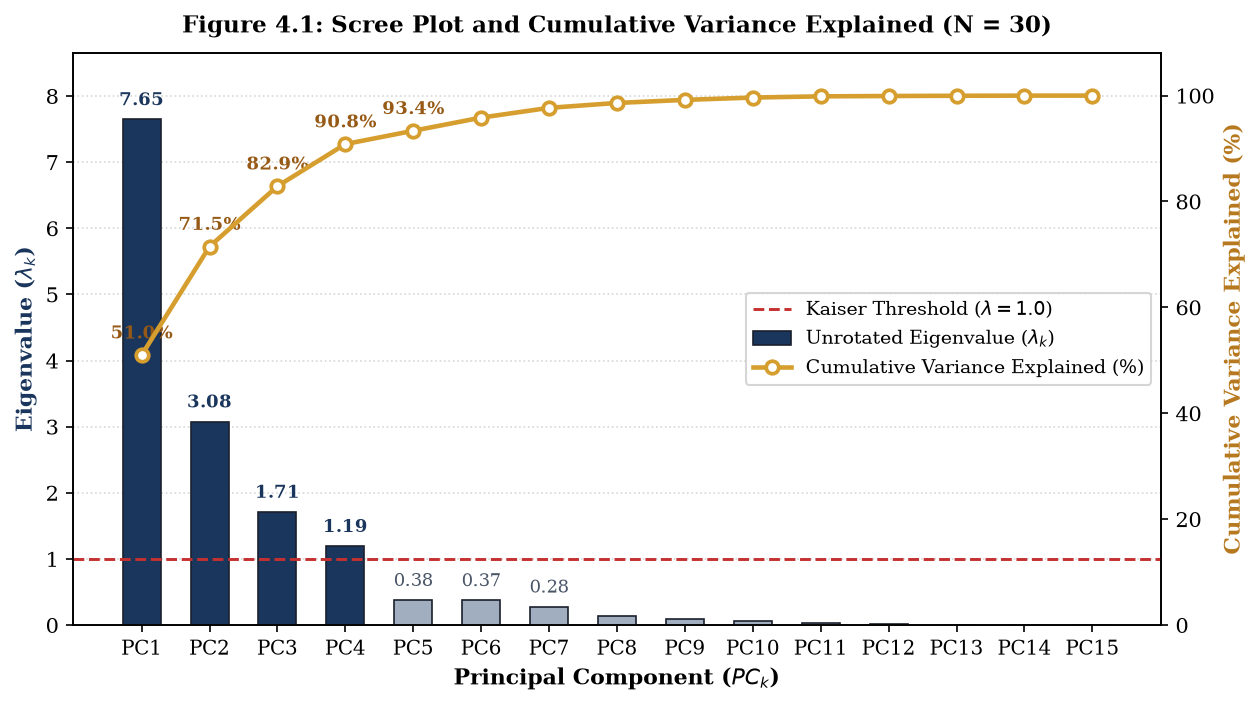

In [10]:
# ==============================================================================
# CELL 9: FIGURE 4.1 - SCREE PLOT & CUMULATIVE VARIANCE EXPLAINED
# ==============================================================================

plt.rcParams['font.family'] = 'DejaVu Serif'

fig, ax1 = plt.subplots(figsize=(8.5, 4.8), dpi=150)
comps = np.arange(1, len(eigvals) + 1)

ax1.bar(
    comps, eigvals,
    color=['#1B365D' if v > 1.0 else '#A0AEC0' for v in eigvals],
    width=0.56, edgecolor='#1A202C', linewidth=0.8, zorder=3,
    label='Unrotated Eigenvalue ($\lambda_k$)'
)
ax1.axhline(1.0, color='#C53030', linestyle='--', linewidth=1.4, zorder=4, label='Kaiser Threshold ($\lambda = 1.0$)')
ax1.set_xlabel('Principal Component ($PC_k$)', fontsize=10.5, fontweight='bold')
ax1.set_ylabel('Eigenvalue ($\lambda_k$)', fontsize=10.5, fontweight='bold', color='#1B365D')
ax1.set_xticks(comps)
ax1.set_xticklabels([f'PC{i}' for i in comps], fontsize=9.5)
ax1.set_ylim(0, max(eigvals) + 1.0)
ax1.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)

for i, v in enumerate(eigvals):
    if v >= 0.15:
        ax1.text(
            comps[i], v + 0.15, f'{v:.2f}', ha='center', va='bottom', fontsize=8.5,
            fontweight='bold' if v > 1.0 else 'normal',
            color='#1B365D' if v > 1.0 else '#4A5568'
        )

ax2 = ax1.twinx()
ax2.plot(
    comps, cum_var, color='#D69E2E', marker='o', markersize=6.0, linewidth=2.2,
    markerfacecolor='#FFFFFF', markeredgewidth=1.8, zorder=5,
    label='Cumulative Variance Explained (%)'
)
ax2.set_ylabel('Cumulative Variance Explained (%)', fontsize=10.5, fontweight='bold', color='#B7791F')
ax2.set_ylim(0, 108)

for i in range(min(5, len(cum_var))):
    ax2.annotate(
        f'{cum_var[i]:.1f}%', (comps[i], cum_var[i]), textcoords="offset points",
        xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold', color='#975A16'
    )

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', frameon=True, facecolor='white', fontsize=9.0)
plt.title('Figure 4.1: Scree Plot and Cumulative Variance Explained (N = 30)', fontsize=11.0, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig("fig4_1_scree.png", dpi=300)
plt.show()


### Step 7B (Cell 10): Figure 4.2 — Varimax-Rotated Component Loadings Profile

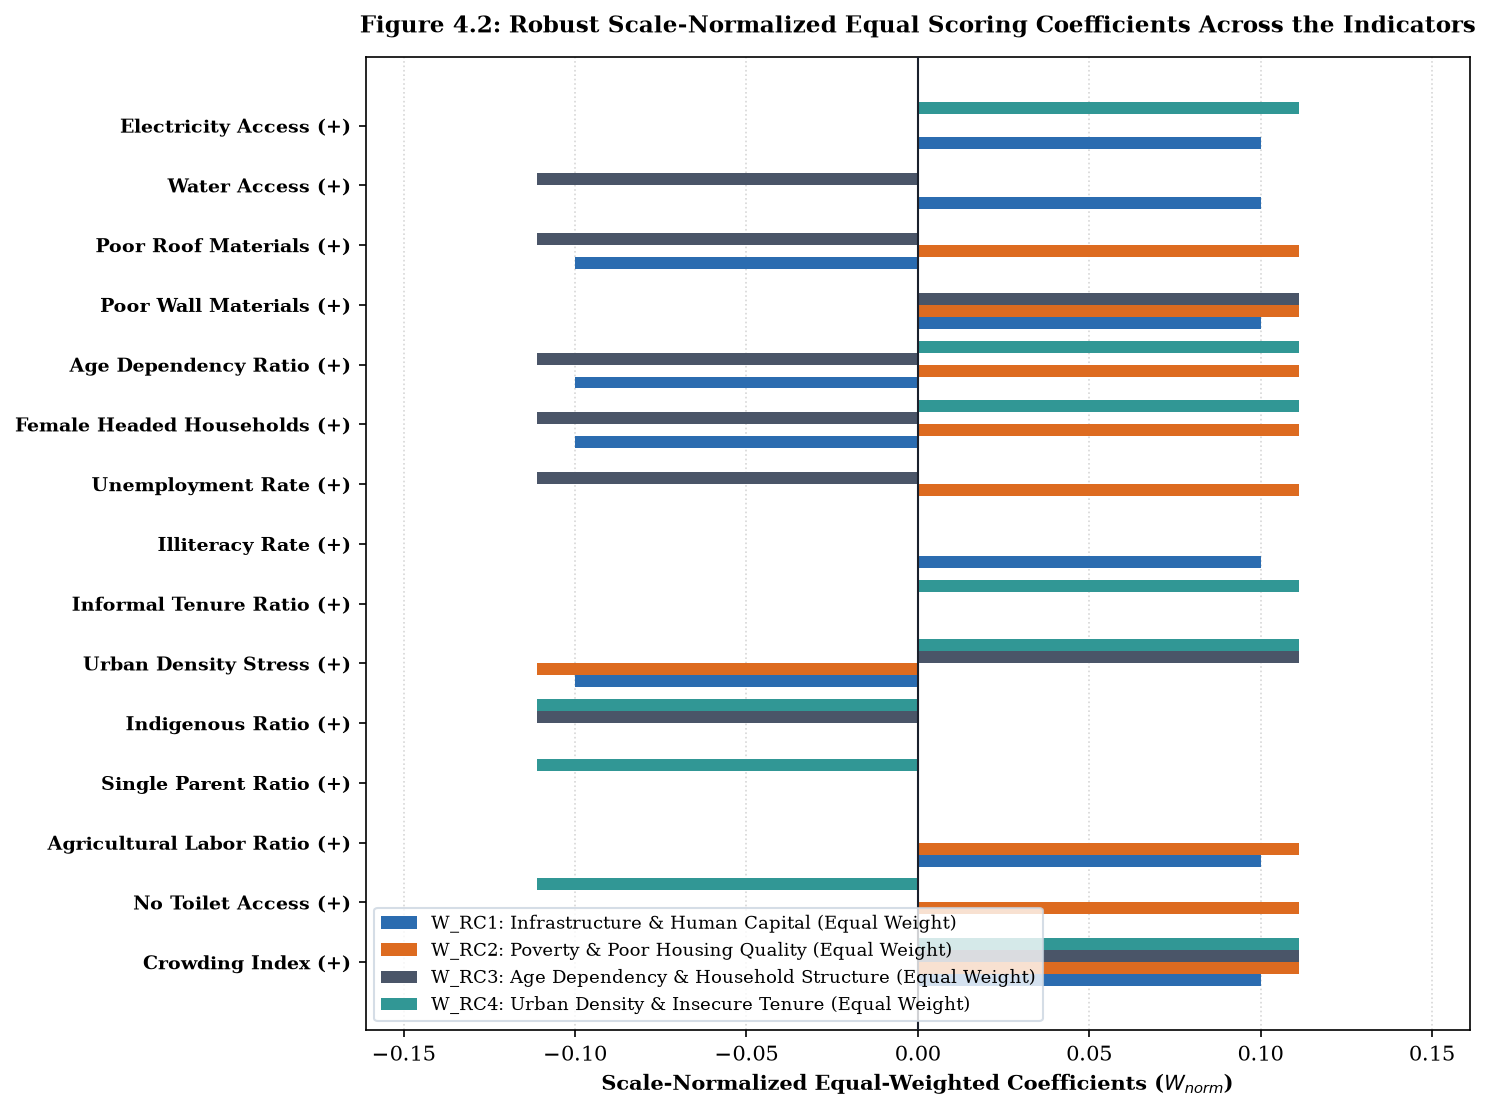

In [11]:
# ==============================================================================
# CELL 10: FIGURE 4.2 - ROBUST EQUAL-WEIGHTED COEFFICIENTS PROFILE (DYNAMIC)
# ==============================================================================

# 1. Dynamically construct the scale-normalized weights directly from load_rot
# This perfectly mirrors the internal threshold scoring logic of Cell 5 and Cell 8
loading_threshold = 0.35
m_components = load_rot.shape[1]
p_variables = load_rot.shape[0]

# Initialize a discrete binary weight blueprint matching your structural dimensions
w_blueprint = np.zeros((m_components, p_variables))
for comp_idx in range(m_components):
    significant_mask = np.abs(load_rot[:, comp_idx]) >= loading_threshold
    w_blueprint[comp_idx, significant_mask] = np.sign(load_rot[significant_mask, comp_idx])

# Apply cluster scale-normalization (dividing by the count of active items per component)
active_counts = np.sum(np.abs(w_blueprint), axis=1, keepdims=True)
active_counts[active_counts == 0] = 1.0
w_derived_normalized = w_blueprint / active_counts

# 2. Render Figure 4.2 Equal Coefficients Profile
fig, ax = plt.subplots(figsize=(10.0, 7.5), dpi=150)
y_pos = np.arange(p_variables)

# Dynamically pull the sign-aligned structural labels matching your panel data dictionary rules
clean_names = [f"{c.replace('_', ' ').title()} ({'+' if cardinality_rules.get(c.lower(), 1) == 1 else '-'})" for c in cols][::-1]

# Dynamic bar offset and sizing layout to comfortably accommodate 4 components simultaneously
bh = 0.8 / m_components
palette = [ '#2B6CB0', '#DD6B20', '#4A5568', '#319795']
rc_descriptions = {
    0: "Infrastructure & Human Capital",
    1: "Poverty & Poor Housing Quality",
    2: "Age Dependency & Household Structure",
    3: "Urban Density & Insecure Tenure"
}

# Dynamically loop through every single active component to plot grouped rows cleanly
for i in range(m_components):
    offset = (i - (m_components - 1) / 2) * bh
    desc = rc_descriptions.get(i, f"Component {i+1} Dimension")
    ax.barh(y_pos + offset, w_derived_normalized[i, :][::-1], height=bh,
            color=palette[i % len(palette)], label=f'W_RC{i+1}: {desc} (Equal Weight)', zorder=3)

ax.axvline(0, color='#1A202C', linewidth=1.0, zorder=4)
ax.set_yticks(y_pos)
ax.set_yticklabels(clean_names, fontsize=9.0, fontweight='bold')
ax.set_xlabel('Scale-Normalized Equal-Weighted Coefficients ($W_{norm}$)', fontsize=10.0, fontweight='bold')

# Automatically center the geometry symmetrically based on discrete normalized weight bounds
max_w = np.max(np.abs(w_derived_normalized))
ax.set_xlim(-max_w - 0.05, max_w + 0.05)

ax.grid(axis='x', linestyle=':', alpha=0.5, zorder=0)
ax.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#CBD5E0', fontsize=8.5)
plt.title('Figure 4.2: Robust Scale-Normalized Equal Scoring Coefficients Across the Indicators', fontsize=11.0, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("fig4_2_equal_coefficients.png", dpi=300)
plt.show()


### Step 7C (Cell 11): Figure 4.3a — Annual Rescaled $\text{SoVI}'$ Trajectories Across Region XI (2020–2024)

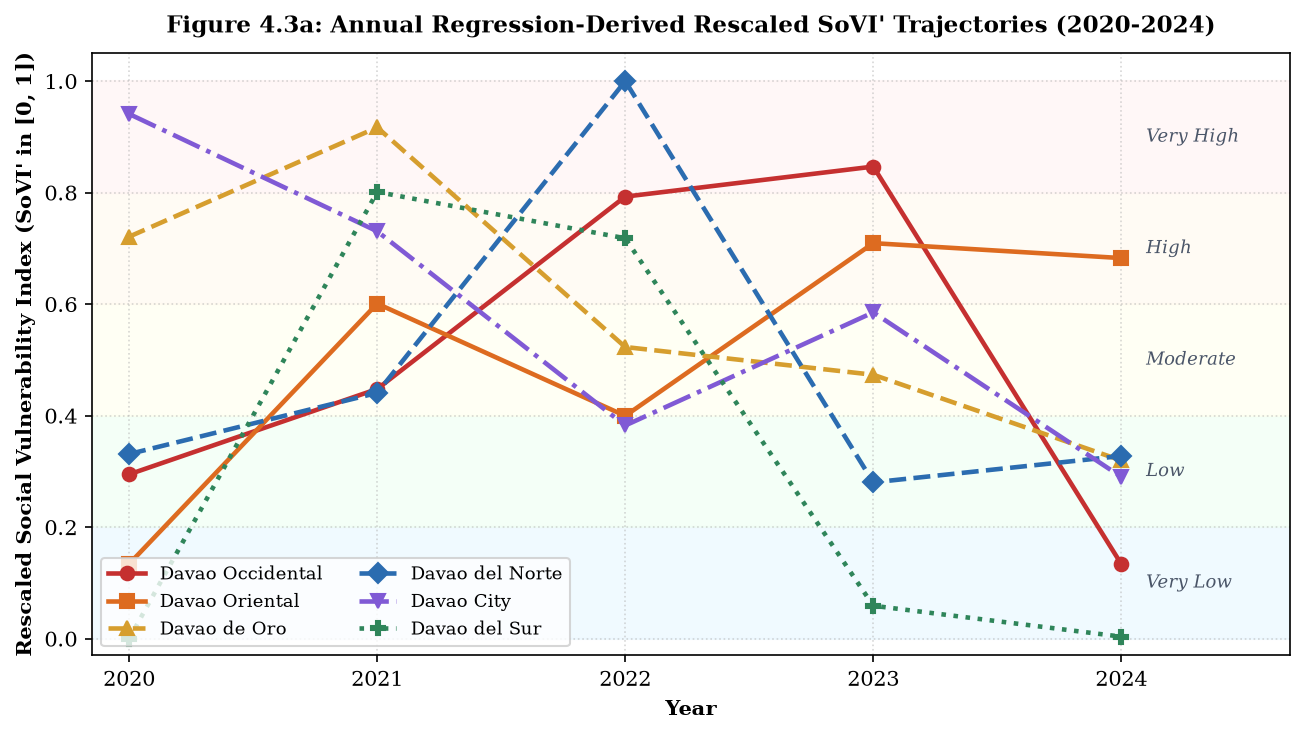

In [12]:
# ==============================================================================
# CELL 11: FIGURE 4.3A - ANNUAL RESCALED SoVI' TRAJECTORIES (2020-2024)
# ==============================================================================

fig, ax_l = plt.subplots(figsize=(8.8, 5.0), dpi=150)

palette_prov = {
    "Davao Occidental": ("#C53030", "o", "-"),
    "Davao Oriental":   ("#DD6B20", "s", "-"),
    "Davao de Oro":     ("#D69E2E", "^", "--"),
    "Davao del Norte":  ("#2B6CB0", "D", "--"),
    "Davao City":       ("#805AD5", "v", "-."),
    "Davao del Sur":    ("#2F855A", "P", ":")
}

tier_bands = [
    (0.00, 0.20, '#EBF8FF', 'Very Low'),
    (0.20, 0.40, '#F0FFF4', 'Low'),
    (0.40, 0.60, '#FFFFF0', 'Moderate'),
    (0.60, 0.80, '#FFFAF0', 'High'),
    (0.80, 1.00, '#FFF5F5', 'Very High')
]

for y0, y1, bg_c, t_lbl in tier_bands:
    ax_l.axhspan(y0, y1, color=bg_c, alpha=0.7, zorder=0)
    ax_l.text(2024.10, (y0 + y1) / 2, t_lbl, va='center', ha='left', fontsize=8.5, fontstyle='italic', color='#4A5568')

for u, (col_c, mk, ls) in palette_prov.items():
    sub = df[df["Province"] == u].sort_values("Year")
    ax_l.plot(
        sub["Year"], sub["SoVI_Norm"], label=u, color=col_c,
        marker=mk, linestyle=ls, linewidth=2.2, markersize=6.5, zorder=4
    )

ax_l.set_title("Figure 4.3a: Annual Regression-Derived Rescaled SoVI' Trajectories (2020-2024)", fontsize=11.0, fontweight='bold', pad=10)
ax_l.set_xlabel('Year', fontsize=10.0, fontweight='bold')
ax_l.set_ylabel("Rescaled Social Vulnerability Index (SoVI' in [0, 1])", fontsize=10.0, fontweight='bold')
ax_l.set_xticks(years)
ax_l.set_xlim(2019.85, 2024.68)
ax_l.set_ylim(-0.03, 1.05)
ax_l.grid(True, linestyle=':', alpha=0.5, zorder=1)
ax_l.legend(loc='lower left', frameon=True, facecolor='white', fontsize=8.8, ncol=2)
plt.tight_layout()
plt.savefig("fig4_3a_trajectories.png", dpi=300)
plt.show()

### Step 7D (Cell 12): Figure 4.3b — 5-Year Mean Rotated Component Decomposition ($\text{RC1}, \text{RC2}, \text{RC3}, \text{RC4}$)

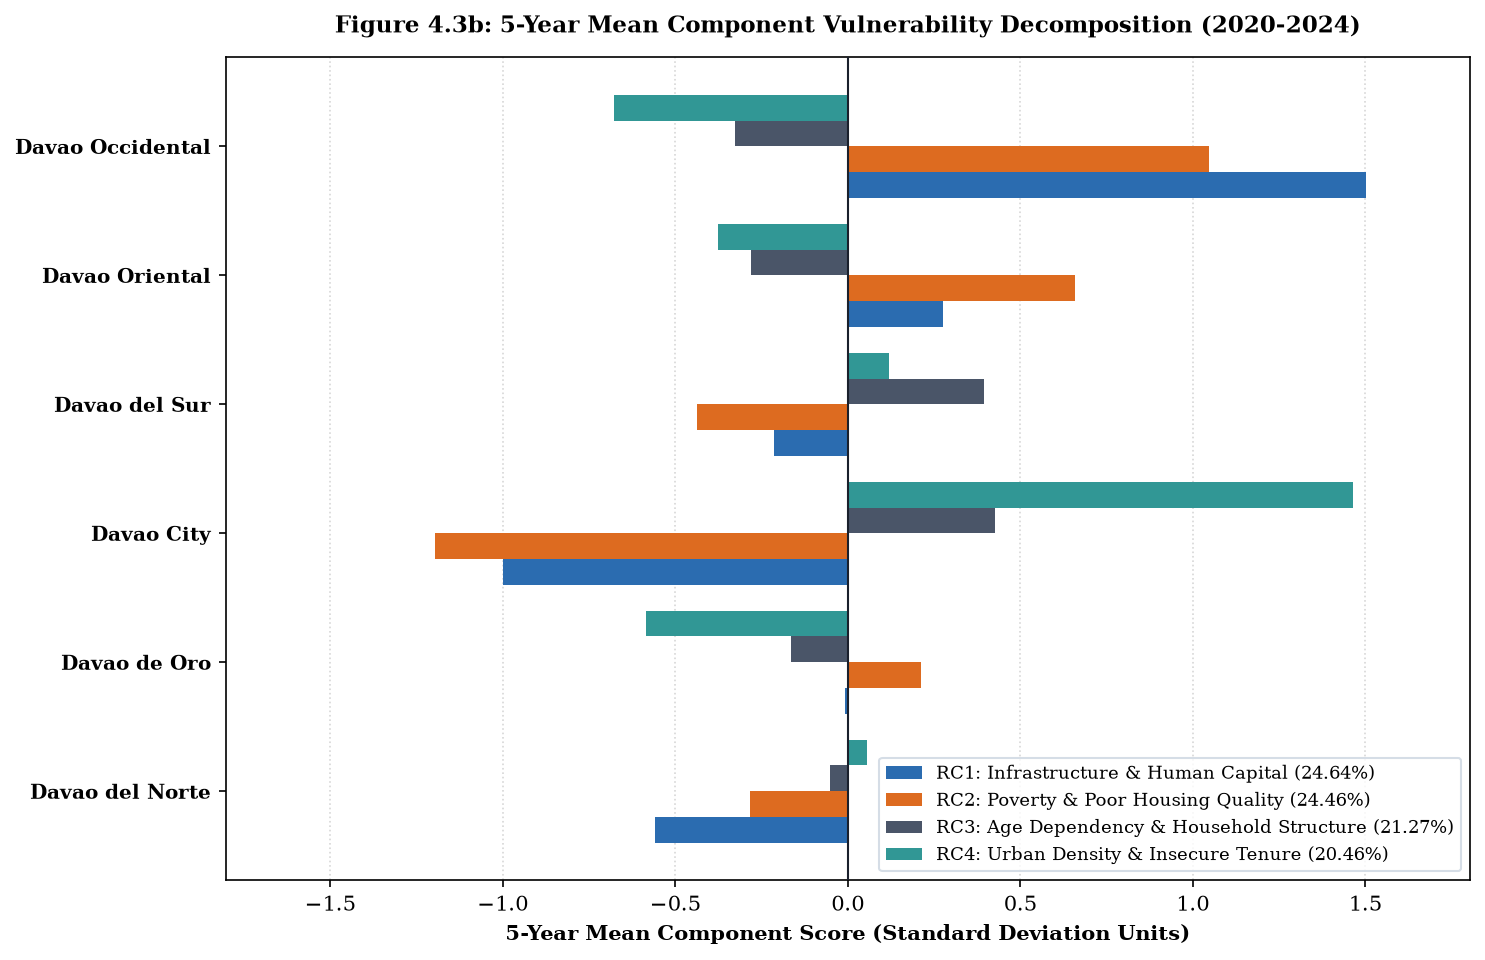

In [13]:
# ==============================================================================
# CELL 12: FIGURE 4.3B - 5-YEAR MEAN COMPONENT VULNERABILITY DECOMPOSITION (DYNAMIC)
# ==============================================================================

fig, ax_r = plt.subplots(figsize=(10.0, 6.5), dpi=150)

prov_order = df_prov_sovi["Province"].values[::-1]
y_p = np.arange(len(prov_order))

# Dynamically pull all available component mean columns present in your summary dataframe
rc_mean_cols = [c for c in df_prov_sovi.columns if c.endswith('_Mean')]
m_components = len(rc_mean_cols)

# Centralized palette and thematic description labels matching your updated 16-indicator layout
palette = [ '#2B6CB0', '#DD6B20', '#4A5568', '#319795']
rc_descriptions = {
    "RC1_Mean": "Infrastructure & Human Capital",
    "RC2_Mean": "Poverty & Poor Housing Quality",
    "RC3_Mean": "Age Dependency & Household Structure",
    "RC4_Mean": "Urban Density & Insecure Tenure"
}

# Dynamically scale cluster grouping heights based on the active component dimension size
bh = 0.8 / m_components
all_extracted_vectors = []

# Dynamically unpack and plot horizontal bars sequentially without structural collision
for i, col_name in enumerate(rc_mean_cols):
    rc_label = col_name.split('_')[0]  # Extracts clean descriptor label (e.g., 'RC1')
    desc = rc_descriptions.get(col_name, f"{rc_label} Dimension")

    # Isolate scores sorted by reverse provincial order bounds
    vector_vals = df_prov_sovi.set_index("Province").loc[prov_order, col_name].values
    all_extracted_vectors.append(vector_vals)

    # Calculate offset metrics to cleanly nest group profiles vertically
    offset = (i - (m_components - 1) / 2) * bh

    ax_r.barh(y_p + offset, vector_vals, height=bh, color=palette[i % len(palette)],
              label=f'{rc_label}: {desc} ({rot_var[i]:.2f}%)', zorder=3)

ax_r.axvline(0, color='#1A202C', linewidth=1.0, zorder=4)
ax_r.set_yticks(y_p)
ax_r.set_yticklabels(prov_order, fontsize=9.5, fontweight='bold')

# Automatically pad limits symmetrically based on standard deviation margins
max_x = np.max(np.abs(all_extracted_vectors))
ax_r.set_xlim(-max_x - 0.3, max_x + 0.3)

# System terminology alignment: Updated from Regression Factor to Component Score
ax_r.set_xlabel('5-Year Mean Component Score (Standard Deviation Units)', fontsize=10.0, fontweight='bold')
ax_r.grid(axis='x', linestyle=':', alpha=0.5, zorder=0)
ax_r.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#CBD5E0', fontsize=8.5)
plt.title('Figure 4.3b: 5-Year Mean Component Vulnerability Decomposition (2020-2024)', fontsize=11.0, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("fig4_3b_decomposition.png", dpi=300)
plt.show()


### Step 7E (Cell 13): Figure 4.4a — Region XI Spatiotemporal Choropleth Maps (2020, 2024, and 5-Year Mean)

In [14]:
# ==============================================================================
# CELL 13: FIGURE 4.4a - REGION XI SPATIOTEMPORAL CHOROPLETH MAPS (DYNAMIC ENGINE)
# ==============================================================================

# --- STEP 1: DYNAMIC VALUE EXTRACTION FROM PANELS ---
prov_col_name = [c for c in df.columns if c.lower() == 'province'][0]
year_col_name = [c for c in df.columns if c.lower() == 'year'][0]

# Extract localized slices from the full panel for baseline (2020) and terminal (2024) periods
df_2020 = df[df[year_col_name] == 2020][[prov_col_name, 'SoVI_Norm', 'Tier']].rename(
    columns={'SoVI_Norm': 'SoVI_2020', 'Tier': 'Tier_2020'}
)
df_2024 = df[df[year_col_name] == 2024][[prov_col_name, 'SoVI_Norm', 'Tier']].rename(
    columns={'SoVI_Norm': 'SoVI_2024', 'Tier': 'Tier_2024'}
)

# Extract longitudinal aggregates from your 5-year summary table
df_means = df_prov_sovi[['Province', 'Mean_SoVI_Norm', 'Mean_Tier']].rename(
    columns={'Province': prov_col_name}
)

# Merge structural fragments into a single local lookup table indexed by Province
df_sovi_extracted = df_2020.merge(df_2024, on=prov_col_name, how='inner')
df_sovi_extracted = df_sovi_extracted.merge(df_means, on=prov_col_name, how='inner')
prov_lookup = df_sovi_extracted.set_index(prov_col_name)

# --- STEP 2: SPATIAL CANVAS BOUNDARIES & GEOMETRIES ---
polys = {
    "Davao del Norte":  [(1.4, 5.3), (3.8, 5.3), (3.8, 3.6), (2.7, 3.3), (1.4, 3.8)],
    "Davao de Oro":     [(3.8, 5.3), (5.8, 5.3), (5.6, 3.1), (4.5, 2.8), (3.8, 3.6)],
    "Davao Oriental":   [(5.8, 5.3), (7.5, 4.9), (7.6, 1.4), (6.0, 0.7), (5.4, 2.2), (4.5, 2.8), (5.6, 3.1)],
    "Davao City":       [(0.6, 3.8), (1.4, 3.8), (2.7, 3.3), (2.6, 2.2), (0.8, 2.2)],
    "Davao del Sur":    [(0.8, 2.2), (2.6, 2.2), (2.7, 1.2), (0.9, 1.2)],
    "Davao Occidental": [(0.9, 1.2), (2.7, 1.2), (3.1, 0.0), (1.3, 0.0)]
}

centroids = {
    "Davao del Norte":  (2.62, 4.38),
    "Davao de Oro":     (4.76, 4.08),
    "Davao Oriental":   (6.48, 2.85),
    "Davao City":       (1.68, 2.95),
    "Davao del Sur":    (1.78, 1.70),
    "Davao Occidental": (1.98, 0.58)
}

tier_colors = {
    "Very Low":  "#90CDF4",
    "Low":       "#9AE6B4",
    "Moderate":  "#FAF089",
    "High":      "#FBD38D",
    "Very High": "#FEB2B2"
}

# --- STEP 3: SUBPLOT RENDER ITERATION ---
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.8), dpi=150)
panel_configs = [
    ("(a) 2020 Pandemic Peak (SoVI')", "SoVI_2020", "Tier_2020"),
    ("(b) 2024 Post-Pandemic Recovery (SoVI')", "SoVI_2024", "Tier_2024"),
    ("(c) 5-Year Pooled Mean (2020-2024)", "Mean_SoVI_Norm", "Mean_Tier")
]

for ax, (p_title, val_col, tier_col) in zip(axes, panel_configs):
    ax.set_facecolor('#EBF8FF')  # Marine Gulf bounding fill

    for u, coords in polys.items():
        # Dynamically draw values from our live query index
        t_val = prov_lookup.loc[u, tier_col]
        s_val = prov_lookup.loc[u, val_col]

        # Build vector shapes
        poly_patch = patches.Polygon(
            coords, closed=True, facecolor=tier_colors[t_val],
            edgecolor='#1A202C', linewidth=1.2, zorder=2
        )
        ax.add_patch(poly_patch)

        # Annotate nodes cleanly
        cx, cy = centroids[u]
        short_u = u.replace("Davao ", "D. ").replace("Occidental", "Occ.").replace("Oriental", "Or.")
        ax.text(
            cx, cy, f"{short_u}\n{s_val:.4f}\n({t_val})",
            ha='center', va='center', fontsize=7.2, fontweight='bold',
            color='#1A202C', zorder=5,
            bbox=dict(boxstyle="round,pad=0.18", facecolor='#FFFFFF', alpha=0.8, edgecolor='#CBD5E1', linewidth=0.5)
        )

    ax.text(3.9, 1.6, "Davao\nGulf", ha='center', va='center', fontsize=8.0, fontstyle='italic', color='#2B6CB0', zorder=3)
    ax.set_xlim(0.2, 7.9)
    ax.set_ylim(-0.3, 5.6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(p_title, fontsize=9.8, fontweight='bold', pad=8)

# --- STEP 4: VISUAL ANCHORS & LEGEND BUILD ---
legend_patches = [
    patches.Patch(facecolor=tier_colors[t], edgecolor='#1A202C', label=f"{t} ({rng})")
    for t, rng in [
        ("Very Low", "0.00-0.20"), ("Low", "0.21-0.40"),
        ("Moderate", "0.41-0.60"), ("High", "0.61-0.80"),
        ("Very High", "0.81-1.00")
    ]
]
fig.legend(handles=legend_patches, loc='lower center', ncol=5, frameon=True, facecolor='white', fontsize=8.5, bbox_to_anchor=(0.5, 0.02))
plt.tight_layout(rect=[0, 0.08, 1, 0.98])
plt.savefig("fig4_4a_poly_spatial_map.png", dpi=300)
plt.show()


KeyError: "['Tier'] not in index"

### Step 7F (Cell 14): Figure 4.4b — Region XI Spatiotemporal Choropleth Maps (2020, 2024, and 5-Year Mean)

Streaming Adm2 (Provinces) shapefile from GitHub...
Streaming Adm3 (Municipalities & Cities) shapefile from GitHub...
Loading Adm2 (Provinces): ph_adm2_shapefile\PH_Adm2_ProvDists.shp
Loading Adm3 (Municipalities & Cities): ph_adm3_shapefile\PH_Adm3_MuniCities.shp
  Davao City extracted from Adm3: 1 feature(s) found.
Relational match complete. Elements mapped: 6 / 6 target areas.

Categorical dashboard rendering completed successfully. Graphic exported to path: 'fig4_4b_geo_spatial_map.png'


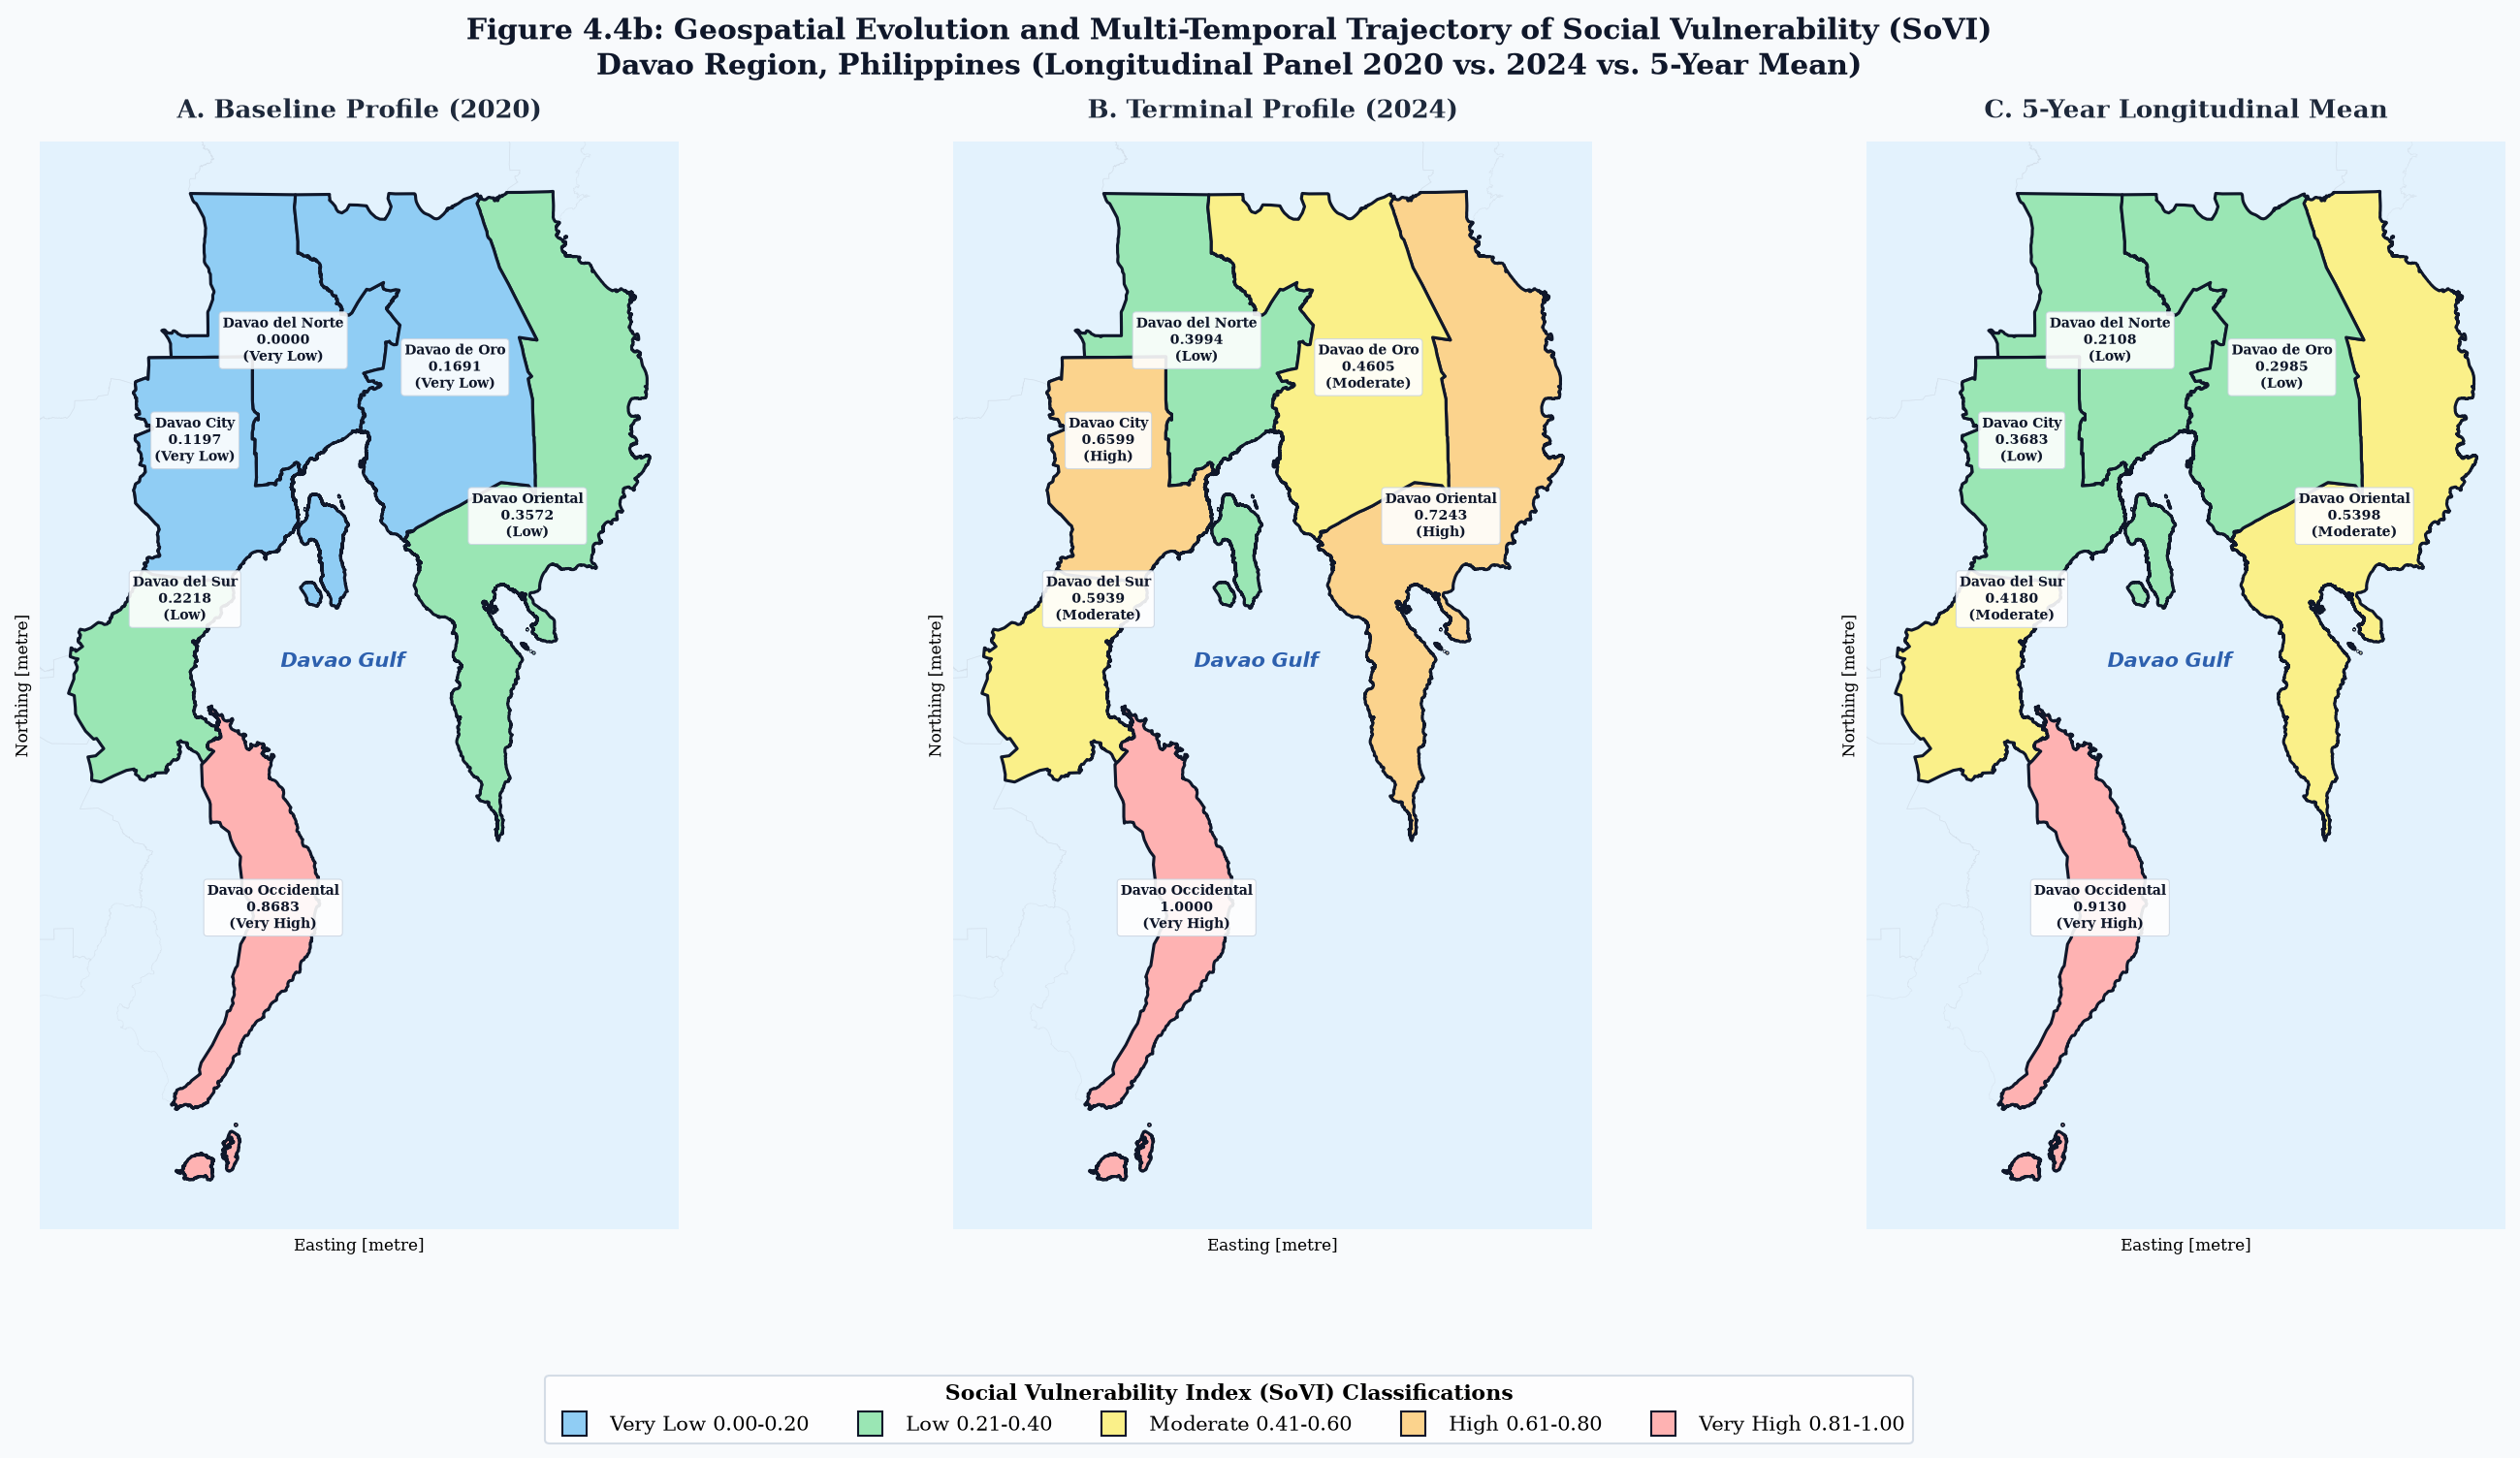

In [ ]:
# ==============================================================================
# CELL 14: FIGURE 4.4b - REGION XI SPATIOTEMPORAL GEOSPATIAL MAPS (2020, 2024, MEAN)
# ==============================================================================
import os
import io
import urllib.request
import zipfile
from shapely.geometry import Point

prov_col_name = [c for c in df.columns if c.lower() == 'province'][0]
year_col_name = [c for c in df.columns if c.lower() == 'year'][0]

# 1. Pull 2020 and 2024 slices directly from the full panel dataframe (df)
df_2020 = df[df[year_col_name] == 2020][[prov_col_name, 'SoVI_Norm', 'Tier']].rename(
    columns={'SoVI_Norm': 'SoVI_2020', 'Tier': 'Tier_2020'}
)
df_2024 = df[df[year_col_name] == 2024][[prov_col_name, 'SoVI_Norm', 'Tier']].rename(
    columns={'SoVI_Norm': 'SoVI_2024', 'Tier': 'Tier_2024'}
)

# 2. Extract longitudinal aggregates from the 5-year summary table
df_means = df_prov_sovi[['Province', 'Mean_SoVI_Norm', 'Mean_Tier']].rename(
    columns={'Province': prov_col_name}
)

# 3. Merge structural fragments into a single local lookup table indexed by Province
df_sovi_extracted = df_2020.merge(df_2024, on=prov_col_name, how='inner')
df_sovi_extracted = df_sovi_extracted.merge(df_means, on=prov_col_name, how='inner')
prov_lookup = df_sovi_extracted.set_index(prov_col_name)

extract_dir = "ph_adm2_shapefile"
extract_dir_adm3 = "ph_adm3_shapefile"

# --- Download Adm2 (Provinces) ---
zip_url_adm2 = "https://github.com/faeldon/philippines-psgc-shapefiles/releases/latest/download/PH_Adm2_ProvDists.shp.zip"
print("Streaming Adm2 (Provinces) shapefile from GitHub...")
req = urllib.request.Request(zip_url_adm2, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    with zipfile.ZipFile(io.BytesIO(response.read())) as zip_ref:
        zip_ref.extractall(extract_dir)

shp_file_adm2 = [f for f in os.listdir(extract_dir) if f.endswith('.shp')][0]
shp_path_adm2 = os.path.join(extract_dir, shp_file_adm2)

# --- Download Adm3 (Municipalities & Cities) ---
zip_url_adm3 = "https://github.com/faeldon/philippines-psgc-shapefiles/releases/latest/download/PH_Adm3_MuniCities.shp.zip"
print("Streaming Adm3 (Municipalities & Cities) shapefile from GitHub...")
req = urllib.request.Request(zip_url_adm3, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    with zipfile.ZipFile(io.BytesIO(response.read())) as zip_ref:
        zip_ref.extractall(extract_dir_adm3)

shp_file_adm3 = [f for f in os.listdir(extract_dir_adm3) if f.endswith('.shp')][0]
shp_path_adm3 = os.path.join(extract_dir_adm3, shp_file_adm3)

print(f"Loading Adm2 (Provinces): {shp_path_adm2}")
ph_provinces = gpd.read_file(shp_path_adm2)

print(f"Loading Adm3 (Municipalities & Cities): {shp_path_adm3}")
ph_municities = gpd.read_file(shp_path_adm3)

# The name column in Adm3 is 'adm3_en' (Level 3 naming convention)
target_name_col_adm3 = 'adm3_en'

# Filter for Davao City specifically
davao_city_mask = ph_municities[target_name_col_adm3].str.contains(
    r'DAVAO', case=False, na=False
) & ph_municities[target_name_col_adm3].str.contains(
    r'CITY|DABAW', case=False, na=False
)
# Exclude "Davao de Oro City" (Mati) or other Davao-region cities if they appear
davao_city_mask = davao_city_mask & ~ph_municities[target_name_col_adm3].str.contains(
    r'ORIENTAL|OCCIDENTAL|DE ORO|DEL NORTE|DEL SUR', case=False, na=False
)

davao_city_gdf = ph_municities[davao_city_mask].copy()

# Safety check: if the regex didn't catch it, try exact/partial match
if len(davao_city_gdf) == 0:
    print("  ⚠ Regex missed Davao City, trying direct name match...")
    davao_city_gdf = ph_municities[
        ph_municities[target_name_col_adm3].str.strip().str.upper().isin(
            ['DAVAO CITY', 'DAVAO', 'CITY OF DAVAO', 'DAVAO CITY (HUC)']
        )
    ].copy()

print(f"  Davao City extracted from Adm3: {len(davao_city_gdf)} feature(s) found.")

target_name_col = 'adm2_en'  # Adm2 name column

def normalize_text_key(val):
    if pd.isna(val): return ""
    v = str(val).strip().upper().replace('_', ' ').replace('-', ' ')

    if 'DAVAO' in v and 'CITY' in v:
        return 'DAVAO CITY'

    if 'DAVAO' in v or 'COMPOSTELA' in v:
        if 'ORO' in v or 'COMPOSTELA' in v: return 'DAVAO DE ORO'
        if 'NORTE' in v: return 'DAVAO DEL NORTE'
        if 'OCCIDENTAL' in v: return 'DAVAO OCCIDENTAL'
        if 'ORIENTAL' in v: return 'DAVAO ORIENTAL'
        if 'SUR' in v: return 'DAVAO DEL SUR'
        if v == 'DAVAO': return 'DAVAO CITY'
    return v

# Normalize Adm2 provinces
ph_provinces['clean_key'] = ph_provinces[target_name_col].apply(normalize_text_key)

# Normalize Davao City from Adm3
davao_city_gdf['clean_key'] = davao_city_gdf[target_name_col_adm3].apply(normalize_text_key)

# Force the key to match our dataframe
davao_city_gdf['clean_key'] = 'DAVAO CITY'
davao_city_gdf['Province'] = 'Davao City'

# Normalize the SoVI dataframe
df_sovi_extracted['clean_key'] = df_sovi_extracted['Province'].apply(normalize_text_key)

# Get the 5 provinces from Adm2
province_targets = ph_provinces[ph_provinces['clean_key'].isin(df_sovi_extracted['clean_key'])].copy()

# Combine: 5 provinces + 1 independent city (only keep shared columns)
combined_targets = gpd.GeoDataFrame(
    pd.concat([
        province_targets[['geometry', 'clean_key']],
        davao_city_gdf[['geometry', 'clean_key']]
    ], ignore_index=True)
)
combined_targets.crs = ph_provinces.crs

# Merge with SoVI data (brings in Province, SoVI values, tiers)
merged_map = combined_targets.merge(df_sovi_extracted, on='clean_key', how='inner')

# Merge with SoVI data
merged_map = combined_targets.merge(df_sovi_extracted, on='clean_key', how='inner')

background_philippines = ph_provinces[~ph_provinces['clean_key'].isin(df_sovi_extracted['clean_key'])]

print(f"Relational match complete. Elements mapped: {len(merged_map)} / 6 target areas.")


# Hardcoding a highly contrasting qualitative color scheme to distinctly isolate brackets
tier_colors = {
    "Very Low":  "#90CDF4",
    "Low":       "#9AE6B4",
    "Moderate":  "#FAF089",
    "High":      "#FBD38D",
    "Very High": "#FEB2B2"
}

ordered_tiers = [("Very Low", "0.00-0.20"), ("Low", "0.21-0.40"), ("Moderate", "0.41-0.60"), ("High", "0.61-0.80"), ("Very High", "0.81-1.00")]

gulf_wgs84 = gpd.GeoSeries([Point(125.78, 6.75)], crs="EPSG:4326")
gulf_projected = gulf_wgs84.to_crs(merged_map.crs)
gulf_x = gulf_projected.geometry.iloc[0].x
gulf_y = gulf_projected.geometry.iloc[0].y


# --- Initialize Figure Canvas ---
fig, axes = plt.subplots(1, 3, figsize=(24, 11), dpi=150)
fig.patch.set_facecolor('#F8FAFC')

plot_configurations = [
    {'column': 'SoVI_2020', 'tier': 'Tier_2020', 'title': 'A. Baseline Profile (2020)'},
    {'column': 'SoVI_2024', 'tier': 'Tier_2024', 'title': 'B. Terminal Profile (2024)'},
    {'column': 'Mean_SoVI_Norm', 'tier': 'Mean_Tier', 'title': 'C. 5-Year Longitudinal Mean'}
]

vmin, vmax = 0.0000, 1.0000
cmap = plt.cm.OrRd

for idx, config in enumerate(plot_configurations):
    ax = axes[idx]
    
    # Set background color to marine blue for the ocean/gulf spaces
    ax.set_facecolor('#E3F2FD') 

    # --- LAYER 1: Transparent National Footprint (The Rest of the Philippines) ---
    background_philippines.plot(
        ax=ax,
        facecolor='none',
        edgecolor='#CBD5E1',
        linewidth=0.3,
        alpha=0.4
    )

    # --- LAYER 2: Foreground Highlighting ---
    merged_map['assigned_color'] = merged_map['Province'].map(
        lambda prov: tier_colors[prov_lookup.loc[prov, config['tier']]]
    )

    merged_map.plot(
        color=merged_map['assigned_color'],
        edgecolor='#0F172A',
        linewidth=1.5,
        antialiased=True,
        ax=ax,
        zorder=2 # Land masses drawn above the water backdrop
    )

    # --- LAYER 3: Dynamic Label Positioning & Collision Prevention ---
    for _, row in merged_map.iterrows():
        prov = row['Province']

        t_val = prov_lookup.loc[prov, config['tier']]
        s_val = prov_lookup.loc[prov, config['column']]

        centroid = row['geometry'].representative_point()
        lon, lat = centroid.x, centroid.y

        # Manual offset adjustments for optimal spatial alignment
        # (Note: keeping original offset shifts intact relative to your project projection units)

        bounds = merged_map.total_bounds
        ax.set_xlim([bounds[0] - (bounds[2]-bounds[0])*0.05, bounds[2] + (bounds[2]-bounds[0])*0.05])
        ax.set_ylim([bounds[1] - (bounds[3]-bounds[1])*0.05, bounds[3] + (bounds[3]-bounds[1])*0.05])

        if prov == 'Davao City':
            lat += (bounds[3] - bounds[1]) * 0.03
            lon -= (bounds[2] - bounds[0]) * 0.01
        elif prov == 'Davao del Sur':
            lat -= (bounds[3] - bounds[1]) * 0.03
            lon -= (bounds[2] - bounds[0]) * 0.01
        elif prov == 'Davao Occidental':
            lon -= (bounds[2] - bounds[0]) * 0.02

        label_text = f"{prov}\n{s_val:.4f}\n({t_val})"

        ax.text(
            lon, lat, label_text,
            fontsize=6.8,
            fontweight='bold',
            color='#0F172A',
            ha='center', va='center',
            zorder=4,
            bbox=dict(boxstyle="round,pad=0.25", facecolor='#FFFFFF', alpha=0.9, edgecolor='#CBD5E1', linewidth=0.5)
        )

    # --- Renders the Davao Gulf label using the correctly projected coordinates ---
    ax.text(
        gulf_x, gulf_y,
        "Davao Gulf",
        color="#0D47A1",             # Dark blue tone
        fontsize=10.0,
        fontweight='bold',
        fontstyle='italic',
        family='sans-serif',
        ha='center', va='center',
        alpha=0.85,
        zorder=3                     # Sits directly on the ocean water layer
    )

    # --- LAYER 4: GEOGRAPHIC ZOOM WINDOW FRAMING ---
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_title(config['title'], fontsize=12.5, fontweight='bold', pad=12, color='#1E293B')


legend_patches = [
    plt.Line2D([0], [0], marker='s', color='none', markerfacecolor=tier_colors[t],
               markeredgecolor='#0F172A', markersize=12, label=f"{t} {rng}")
    for t, rng in ordered_tiers
]

fig.legend(
    handles=legend_patches,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.06),
    ncol=5,
    fontsize=10.0,
    frameon=True,
    facecolor='#FFFFFF',
    edgecolor='#CBD5E1',
    title="Social Vulnerability Index (SoVI) Classifications",
    title_fontproperties={'weight': 'bold', 'size': 10.5}
)

plt.suptitle(
    "Figure 4.4b: Geospatial Evolution and Multi-Temporal Trajectory of Social Vulnerability (SoVI)\n"
    "Davao Region, Philippines (Longitudinal Panel 2020 vs. 2024 vs. 5-Year Mean)",
    fontsize=14.5,
    fontweight='bold',
    y=0.96,
    color='#0F172A',
    ha='center'
)

plt.subplots_adjust(bottom=0.20, wspace=0.04)

output_dashboard = "fig4_4b_geo_spatial_map.png"
plt.savefig(output_dashboard, dpi=300, bbox_inches='tight')
print(f"\nCategorical dashboard rendering completed successfully. Graphic exported to path: '{output_dashboard}'")
plt.show()

### Step 7F (Cell 15): Figure 4.5a — Indicator Jackknife ($N-1$) & Specification Robustness

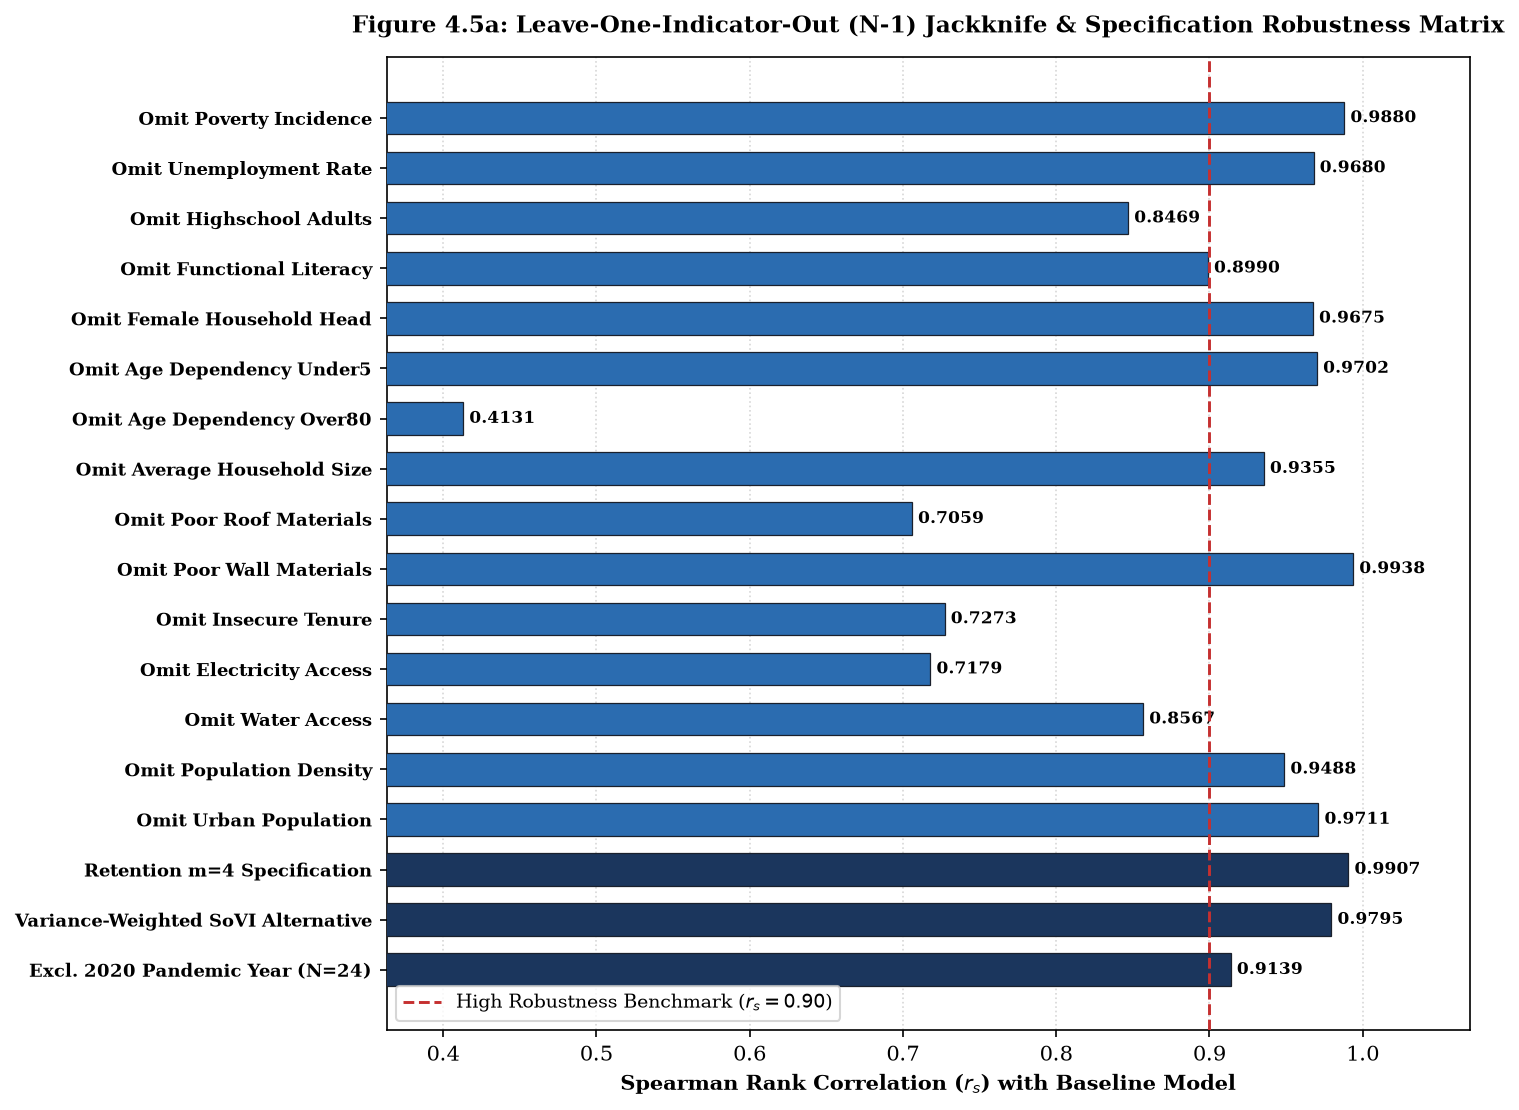

In [ ]:
# ==============================================================================
# CELL 15: FIGURE 4.5A - INDICATOR JACKKNIFE & SPECIFICATION ROBUSTNESS
# ==============================================================================

# Automatically resolve case-sensitivity issues for core tracking columns matching Cell 8
prov_col = [c for c in df.columns if c.lower() == 'province'][0]
year_col = [c for c in df.columns if c.lower() == 'year'][0]
sovi_norm_col = [c for c in df.columns if c.lower() == 'sovi_norm'][0]

fig, ax1 = plt.subplots(figsize=(10.0, 7.5), dpi=150)

# --- 1. DYNAMICALLY RE-RUN SENSITIVITY ENGINE TO EXTRACT EXACT ARRAYS ---
check_labels = []
check_rs = []

# Section 1: Leave-One-Indicator-Out (N-1) Jackknife Loop
for drop_c in cols:
    sub_c = [c for c in cols if c != drop_c]
    _, norm_j = run_pca_sovi(df, sub_c, var_weighted=False)
    rs_all = stats.spearmanr(df[sovi_norm_col], norm_j).statistic

    # Format labels cleanly by transforming underscores into spacing gaps
    clean_lbl = f"Omit {drop_c.replace('_', ' ').title()}"
    check_labels.append(clean_lbl)
    check_rs.append(rs_all)

# Section 3: Specification Structural Alternative Comparisons
# A. Retention m=4 specification test configuration (already unweighted addition baseline)
_, norm_m4 = run_pca_sovi(df, cols, n_comp=4, var_weighted=False)
rs_m4 = stats.spearmanr(df[sovi_norm_col], norm_m4).statistic
check_labels.append("Retention m=4 Specification")
check_rs.append(rs_m4)

# B. Variance-weighted alternative profile check
_, norm_vw = run_pca_sovi(df, cols, var_weighted=True)
rs_vw = stats.spearmanr(df[sovi_norm_col], norm_vw).statistic
check_labels.append("Variance-Weighted SoVI Alternative")
check_rs.append(rs_vw)

# C. Temporal boundary stability filtering test run (Excl. 2020)
df_no20 = df[df[year_col] > 2020].copy().reset_index(drop=True)
_, norm_no20 = run_pca_sovi(df_no20, cols, var_weighted=False)
rs_no20 = stats.spearmanr(df_no20[sovi_norm_col], norm_no20).statistic
check_labels.append("Excl. 2020 Pandemic Year (N=24)")
check_rs.append(rs_no20)

# --- 2. BUILD VERTICAL CHART FROM THE BOTTOM UP ---
# Reverse arrays to maintain a clean sequential top-down rendering
check_labels = check_labels[::-1]
check_rs = check_rs[::-1]

y_c = np.arange(len(check_labels))
# Distinct color blocks isolate Jackknife steps (Light Blue) from System Specs (Dark Corporate Navy)
colors_c = ['#2B6CB0' if "Omit" in lbl else '#1B365D' for lbl in check_labels]

ax1.barh(y_c, check_rs, color=colors_c, height=0.65, edgecolor='#1A202C', linewidth=0.6, zorder=3)
ax1.axvline(0.90, color='#C53030', linestyle='--', linewidth=1.4, label='High Robustness Benchmark ($r_s = 0.90$)', zorder=4)

# Overlay precise text value parameters onto bars
for i, v in enumerate(check_rs):
    ax1.text(v + 0.004, i, f'{v:.4f}', va='center', fontsize=8.0, fontweight='bold')

ax1.set_yticks(y_c)
ax1.set_yticklabels(check_labels, fontsize=8.5, fontweight='bold')
ax1.set_xlim(min(check_rs) - 0.05, 1.07)
ax1.set_xlabel("Spearman Rank Correlation ($r_s$) with Baseline Model", fontsize=10.0, fontweight='bold')
ax1.set_title("Figure 4.5a: Leave-One-Indicator-Out (N-1) Jackknife & Specification Robustness Matrix", fontsize=11.0, fontweight='bold', pad=12)

ax1.grid(axis='x', linestyle=':', alpha=0.5, zorder=0)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9.0)
plt.tight_layout()
plt.savefig("fig4_5a_jackknife_robustness.png", dpi=300)
plt.show()


### Step 7G (Cell 16): Figure 4.5b — Main Pooled PCA $\text{SoVI}'$ vs. Baseline 1 & Baseline 2

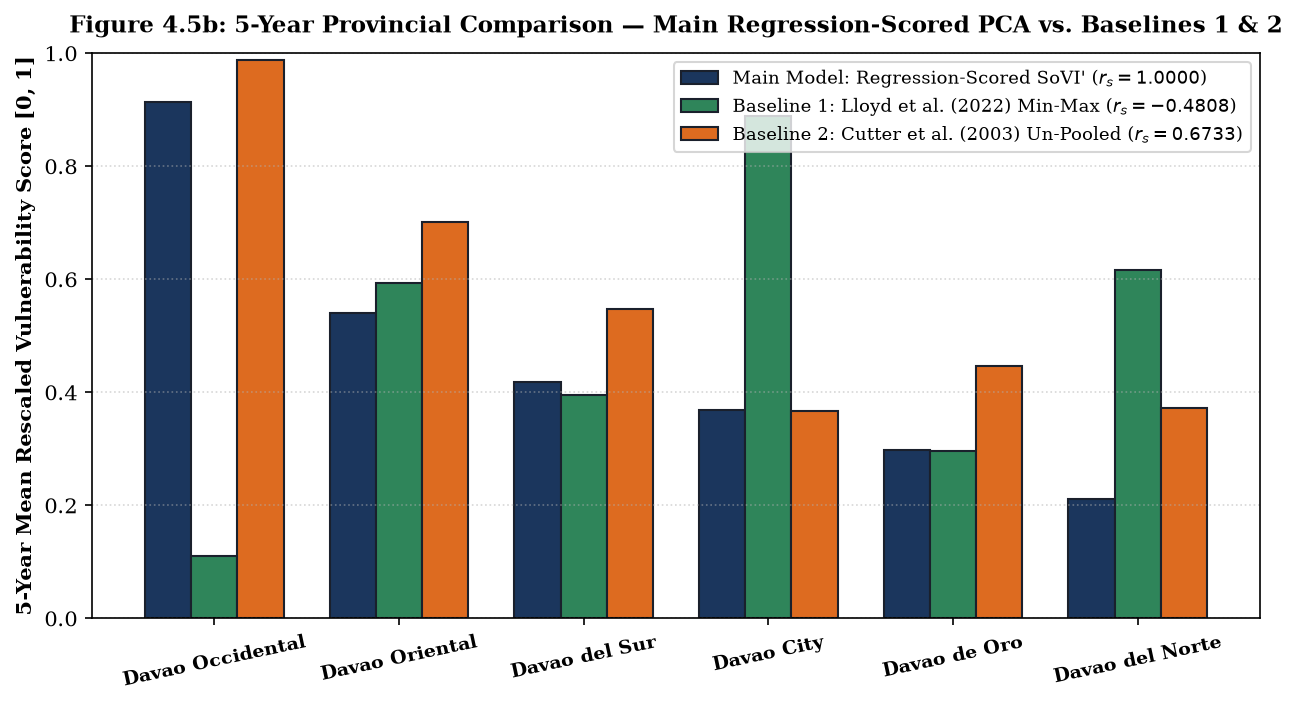

In [ ]:
# ==============================================================================
# CELL 16: FIGURE 4.5B - MAIN POOLED PCA VS. BASELINE 1 & BASELINE 2
# ==============================================================================

fig, ax2 = plt.subplots(figsize=(8.6, 4.8), dpi=150)

x_p = np.arange(len(units))
u_sorted = df_prov_sovi["Province"].values
main_5yr = df.groupby("Province")["SoVI_Norm"].mean().loc[u_sorted].values
b1_5yr   = df.groupby("Province")["Baseline1_Norm"].mean().loc[u_sorted].values
b2_5yr   = df.groupby("Province")["Baseline2_Norm"].mean().loc[u_sorted].values

# Fetch the global comparative validation correlations calculated dynamically in Cell 7
rs_main = 1.0000
rs_b1 = stats.spearmanr(df['SoVI_Norm'], df['Baseline1_Norm']).statistic
rs_b2 = stats.spearmanr(df['SoVI_Norm'], df['Baseline2_Norm']).statistic

w_b = 0.25
ax2.bar(x_p - w_b, main_5yr, width=w_b, color='#1B365D', edgecolor='#1A202C', label=f"Main Model: Regression-Scored SoVI' ($r_s = {rs_main:.4f}$)")
ax2.bar(x_p,       b1_5yr,   width=w_b, color='#2F855A', edgecolor='#1A202C', label=f"Baseline 1: Lloyd et al. (2022) Min-Max ($r_s = {rs_b1:.4f}$)")
ax2.bar(x_p + w_b, b2_5yr,   width=w_b, color='#DD6B20', edgecolor='#1A202C', label=f"Baseline 2: Cutter et al. (2003) Un-Pooled ($r_s = {rs_b2:.4f}$)")

ax2.set_xticks(x_p)
ax2.set_xticklabels(u_sorted, fontsize=9.0, fontweight='bold', rotation=12)
ax2.set_ylabel("5-Year Mean Rescaled Vulnerability Score [0, 1]", fontsize=10.0, fontweight='bold')
ax2.set_ylim(0, 1.0)
ax2.set_title("Figure 4.5b: 5-Year Provincial Comparison — Main Regression-Scored PCA vs. Baselines 1 & 2", fontsize=11.0, fontweight='bold', pad=10)
ax2.grid(axis='y', linestyle=':', alpha=0.5)
ax2.legend(loc='upper right', frameon=True, facecolor='white', fontsize=8.8)
plt.tight_layout()
plt.savefig("fig4_5b_baseline_comparison.png", dpi=300)
plt.show()



### Step 7H (Cell 17): Heatmap 1 — $10 \times 10$ Bivariate Pearson Correlation Matrix Heatmap ($N = 30$)

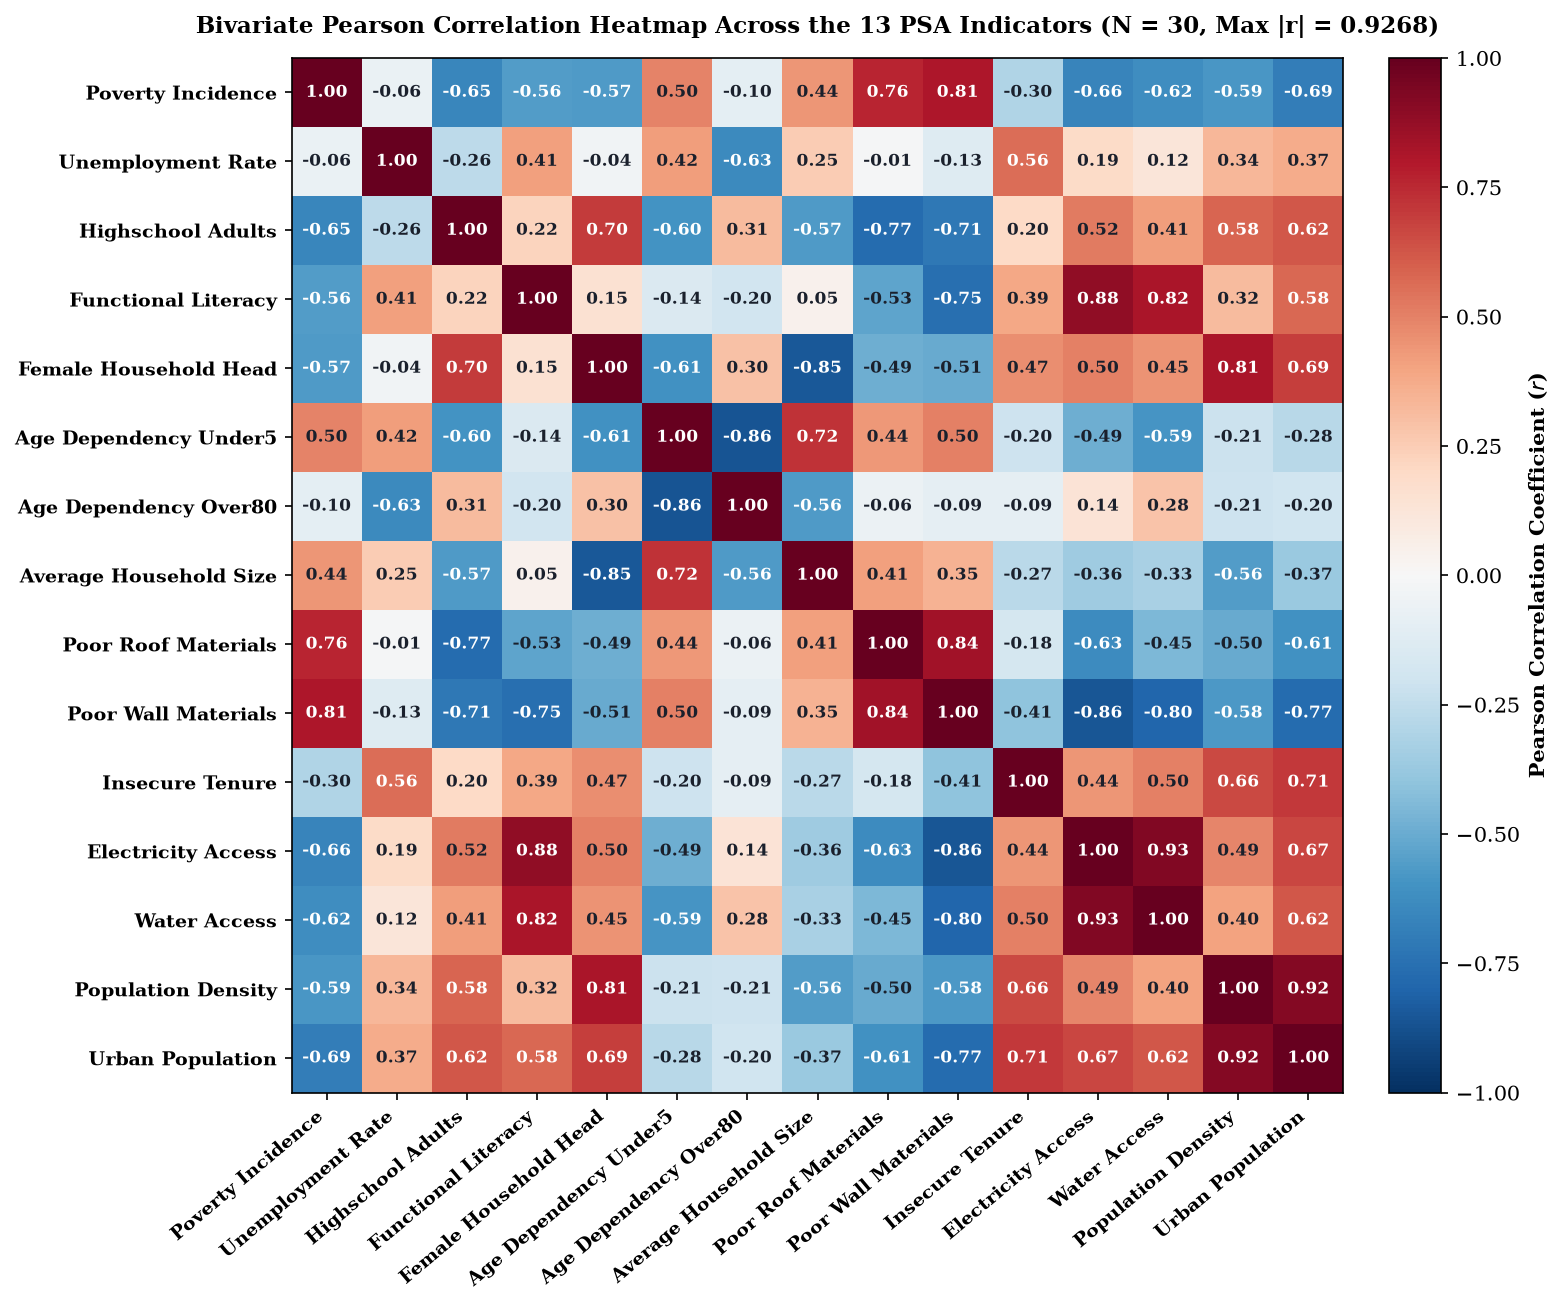

In [ ]:
# ==============================================================================
# CELL 17: HEATMAP 1 - 13x13 PEARSON CORRELATION MATRIX HEATMAP (N = 30)
# ==============================================================================


fig, ax = plt.subplots(figsize=(10.5, 8.8), dpi=150)

# Reformat variable names string inputs for visualization presentation labels
clean_labels = [c.replace('_', ' ') for c in cols]

# Matrix input 'R' holds the actual bivariate values generated during Step 2
im = ax.imshow(R, cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson Correlation Coefficient ($r$)", fontsize=10.0, fontweight="bold")

ax.set_xticks(np.arange(len(clean_labels)))
ax.set_yticks(np.arange(len(clean_labels)))
ax.set_xticklabels(clean_labels, rotation=40, ha="right", fontsize=9.0, fontweight="bold")
ax.set_yticklabels(clean_labels, fontsize=9.0, fontweight="bold")

# Dynamically calculate maximum correlation ceiling to auto-label the plot header text
upper_tri_mask = np.triu(np.ones(R.shape), k=1).astype(bool)
max_bivariate_r = np.max(np.abs(R[upper_tri_mask]))

for i in range(len(clean_labels)):
    for j in range(len(clean_labels)):
        val = R[i, j]
        txt_color = "white" if abs(val) >= 0.55 else "#1A202C"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=8.0, fontweight="bold")

ax.set_title(f"Bivariate Pearson Correlation Heatmap Across the 13 PSA Indicators (N = 30, Max |r| = {max_bivariate_r:.4f})", fontsize=11.0, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("fig_heatmap_1_correlations.png", dpi=300)
plt.show()


### Step 7I (Cell 18): Heatmap 2 — Varimax-Rotated Component Loadings ($\text{RC1}, \text{RC2}, \text{RC3}, \text{RC4[link text](https:// [link text](https://))}$) & Communalities ($h^2$) Heatmap

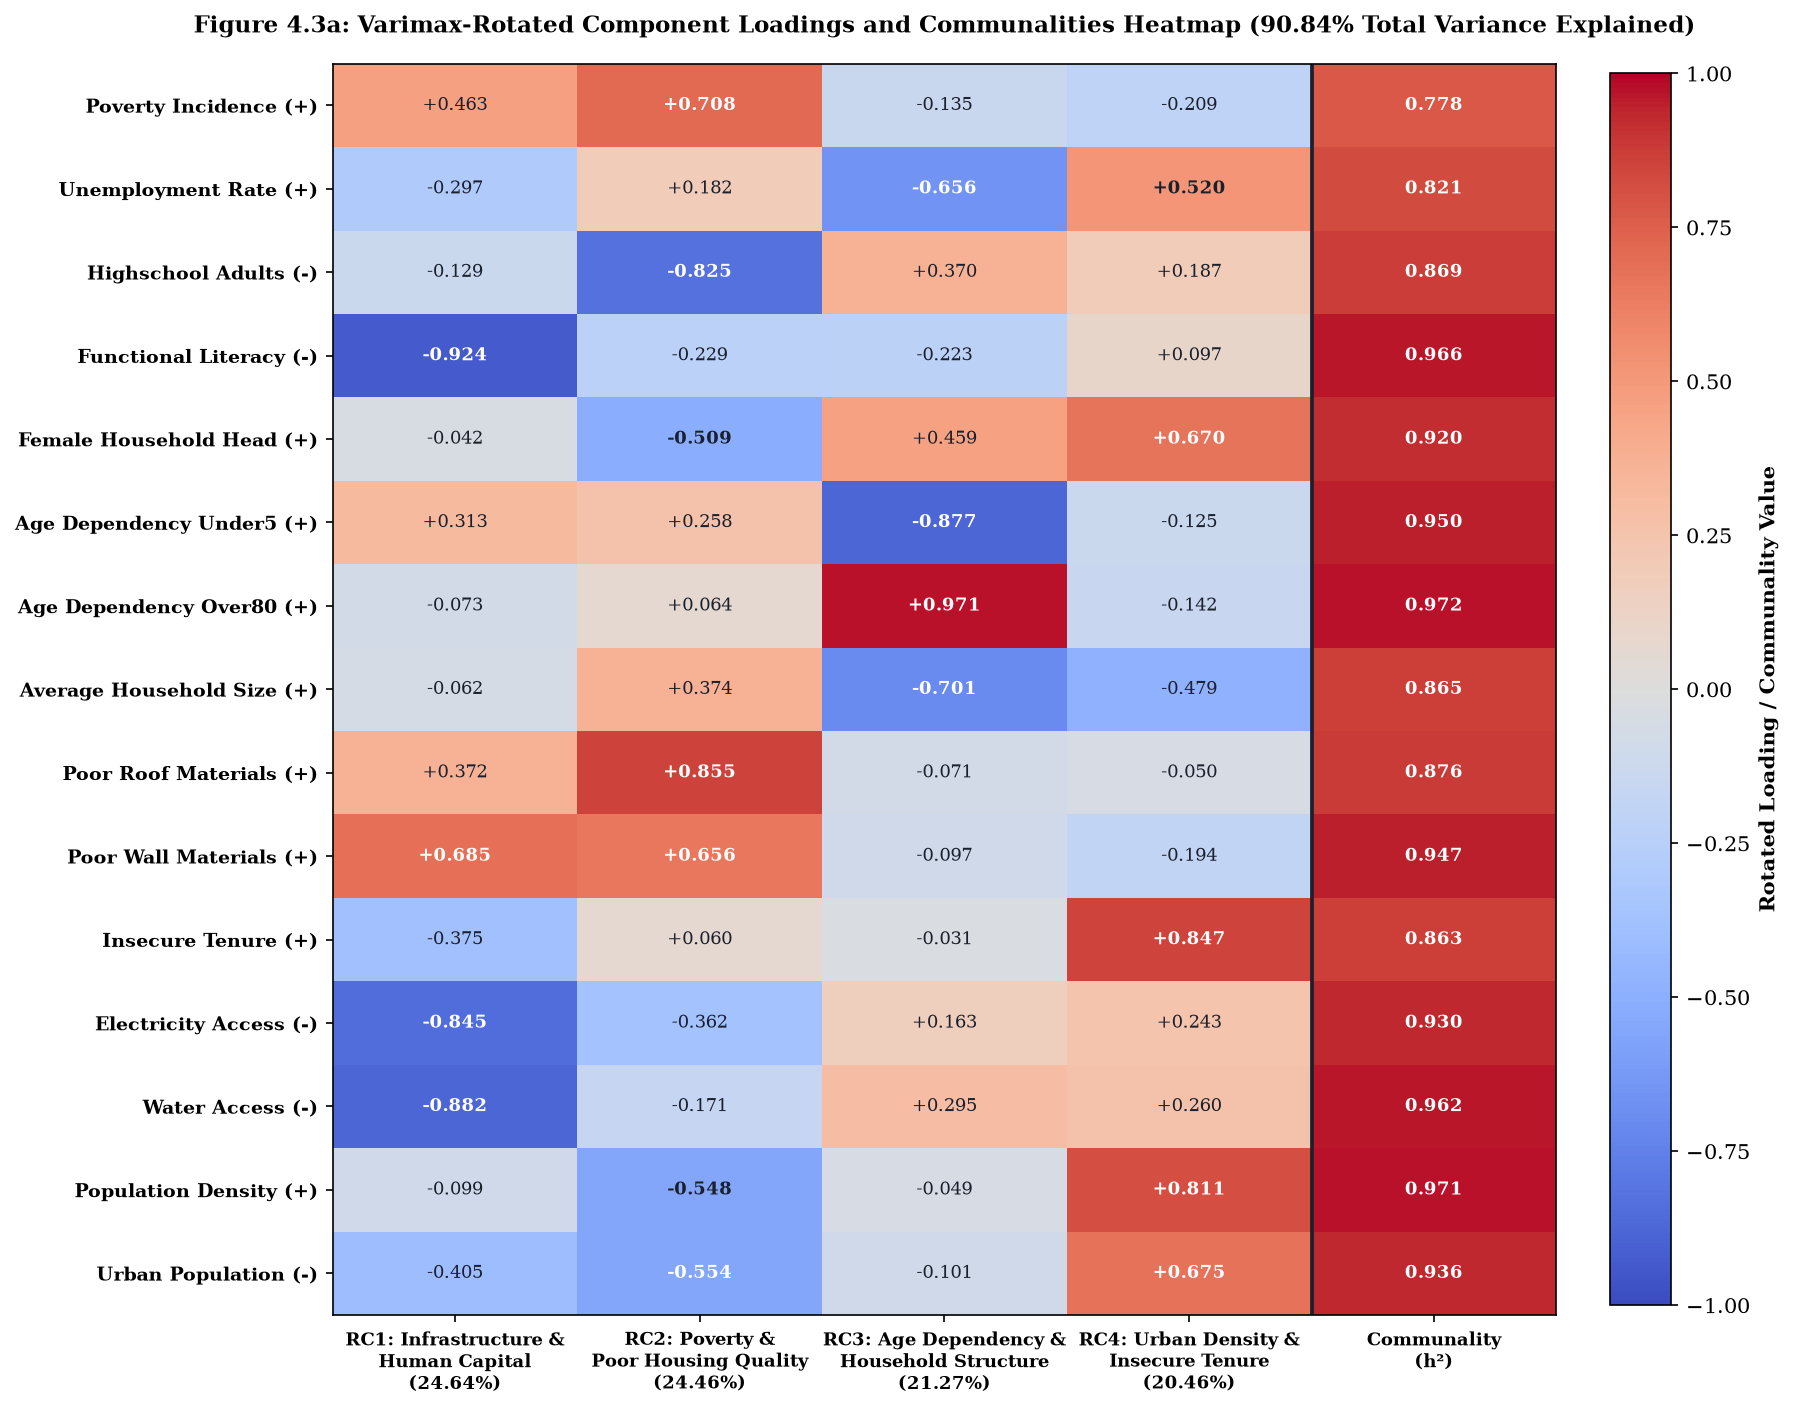

In [ ]:
# ==============================================================================
# CELL 18: HEATMAP 2 - VARIMAX-ROTATED COMPONENT LOADINGS & COMMUNALITIES HEATMAP
# ==============================================================================

fig, ax = plt.subplots(figsize=(12.0, 9.5), dpi=150)

# Dynamically slice all active components from your load_table frame
hm_mat_components = load_table[rc_labels].values
hm_mat_communalities = load_table[["Communality_h2"]].values

# Combine the components matrix and communalities column into a unified heatmap array
hm_mat = np.hstack([hm_mat_components, hm_mat_communalities])

# Dynamically build column headers matching the corrected rotated component configurations
rc_descriptions = {
    0: "Infrastructure &\nHuman Capital",
    1: "Poverty &\nPoor Housing Quality",
    2: "Age Dependency &\nHousehold Structure",
    3: "Urban Density &\nInsecure Tenure"
}

col_headers = [
    f"{rc_labels[i]}: {rc_descriptions.get(i, 'Component Dimension')}\n({rot_var[i]:.2f}%)"
    for i in range(m)
]
col_headers.append("Communality\n(h²)")

# FIXED: Removed .lower() to ensure lookup keys match the capitalized cardinality_rules keys exactly
row_headers = [f"{c.replace('_', ' ').title()} ({'+' if cardinality_rules.get(c, 1) == 1 else '-'})" for c in cols]

# Render the continuous correlation matrix image grid
im = ax.imshow(hm_mat, cmap="coolwarm", vmin=-1.0, vmax=1.0, aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Rotated Loading / Communality Value", fontsize=10.0, fontweight="bold")

ax.set_xticks(np.arange(len(col_headers)))
ax.set_yticks(np.arange(len(row_headers)))
ax.set_xticklabels(col_headers, fontsize=8.5, fontweight="bold")
ax.set_yticklabels(row_headers, fontsize=9.2, fontweight="bold")

# Annotate each grid intersection dynamically with custom color/weight contrast rules
for i in range(hm_mat.shape[0]):
    for j in range(hm_mat.shape[1]):
        val = hm_mat[i, j]
        # High contrast rules for dark background cells (coolwarm thresholds)
        txt_color = "white" if abs(val) >= 0.55 else "#1A202C"

        # Bold strong factor cross-loadings (>= 0.50) or the final communality column
        weight = "bold" if (j < m and abs(val) >= 0.50) or j == m else "normal"

        # Display matching sign tokens (+/-) on rotated components only
        label_text = f"{val:+.3f}" if j < m else f"{val:.3f}"
        ax.text(j, i, label_text, ha="center", va="center", color=txt_color, fontsize=8.5, fontweight=weight)

# Draw a crisp visual separating boundary right before the final communality track
ax.axvline(m - 0.5, color="#1A202C", linewidth=1.8, linestyle="-")

plt.title(f"Figure 4.3a: Varimax-Rotated Component Loadings and Communalities Heatmap ({rot_cum[m-1]:.2f}% Total Variance Explained)", fontsize=11.0, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("fig_heatmap_2_pca_loadings.png", dpi=300)
plt.show()


### Step 7J (Cell 19): Heatmap 3 — Spatiotemporal $\text{SoVI}'$ Matrix Heatmap Across Region XI (2020–2024 & 5-Year Mean)

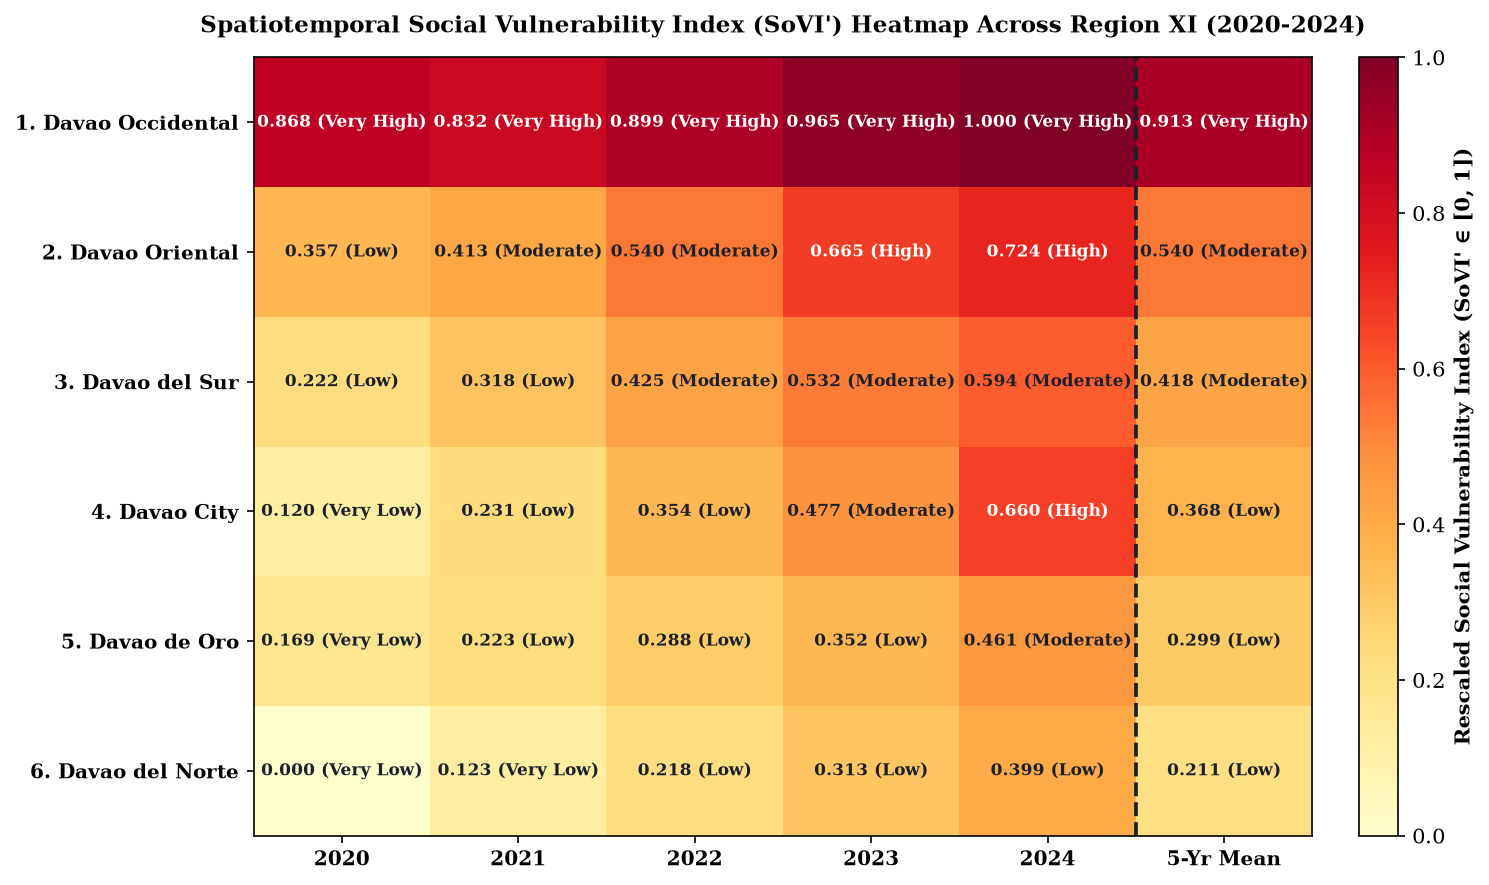

In [ ]:
# ==============================================================================
# CELL 19: HEATMAP 3 - SPATIOTEMPORAL SoVI' MATRIX HEATMAP (PROVINCE x YEAR)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

prov_ordered = df_prov_sovi["Province"].values
pivot_sovi = df.pivot(index="Province", columns="Year", values="SoVI_Norm").loc[prov_ordered, years]
pivot_sovi["5-Yr Mean"] = df_prov_sovi.set_index("Province").loc[prov_ordered, "Mean_SoVI_Norm"]

sovi_mat = pivot_sovi.values
col_lbls = ["2020", "2021", "2022", "2023", "2024", "5-Yr Mean"]

im = ax.imshow(sovi_mat, cmap="YlOrRd", vmin=0.0, vmax=1.0, aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Rescaled Social Vulnerability Index (SoVI' ∈ [0, 1])", fontsize=10.0, fontweight="bold")

ax.set_xticks(np.arange(len(col_lbls)))
ax.set_yticks(np.arange(len(prov_ordered)))
ax.set_xticklabels(col_lbls, fontsize=9.5, fontweight="bold")
ax.set_yticklabels([f"{idx+1}. {p}" for idx, p in enumerate(prov_ordered)], fontsize=9.5, fontweight="bold")

for i in range(sovi_mat.shape[0]):
    for j in range(sovi_mat.shape[1]):
        val = sovi_mat[i, j]
        t_lbl = classify_tier(val)
        txt_color = "white" if val >= 0.62 else "#1A202C"
        ax.text(j, i, f"{val:.3f} ({t_lbl})", ha="center", va="center", color=txt_color, fontsize=8.3, fontweight="bold")

ax.axvline(4.5, color="#1A202C", linewidth=1.8, linestyle="--")
ax.set_title("Spatiotemporal Social Vulnerability Index (SoVI') Heatmap Across Region XI (2020-2024)", fontsize=11.0, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("fig_heatmap_3_spatiotemporal_sovi.png", dpi=300)
plt.show()

### Step 8 (Cell 20): Export Final Spatiotemporal Panel & Provincial Summary CSVs

In [ ]:
# ==============================================================================
# CELL 20: EXPORT FINAL PANEL & PROVINCIAL SUMMARY CSV FILES
# ==============================================================================
# 1. Export Dataframes to CSV
df.to_csv("Region_XI_SoVI_Panel_Results_2020_2024.csv", index=False)
df_prov_sovi.to_csv("Region_XI_SoVI_Provincial_Summary_2020_2024.csv", index=False)

# 2. Define ZIP Archive Names
csv_zip_name = "sovi_tabular_outputs.zip"
img_zip_name = "sovi_visual_plots.zip"

# Image extension definitions
img_extensions = ('.png', '.jpg', '.jpeg', '.svg', '.pdf')

print("Starting dynamic file export process (ignoring folders)...")

# 3. Create Separated ZIP Archives
with zipfile.ZipFile(csv_zip_name, 'w', zipfile.ZIP_DEFLATED) as csv_zip, \
     zipfile.ZipFile(img_zip_name, 'w', zipfile.ZIP_DEFLATED) as img_zip:

    # Scan immediate execution directory
    for file in os.listdir('.'):
        # Ignore subfolders/directories and the newly created zip files themselves
        if os.path.isfile(file) and file not in [csv_zip_name, img_zip_name]:

            # Group Images separately
            if file.lower().endswith(img_extensions):
                print(f" -> Routing Visual to {img_zip_name}: {file}")
                img_zip.write(file)

            # Group CSV/Tabular Data separately
            elif file.lower().endswith('.csv'):
                print(f" -> Routing Data to {csv_zip_name}: {file}")
                csv_zip.write(file)

print(f"\n✅ Export Complete!")
print(f"📁 Tabular Data Archive: {csv_zip_name}")
print(f"🖼️ Images/Plots Archive: {img_zip_name}")

Starting dynamic file export process (ignoring folders)...
 -> Routing Visual to sovi_visual_plots.zip: fig4_1_scree.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_2_equal_coefficients.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_3a_trajectories.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_3b_decomposition.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_4a_poly_spatial_map.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_4b_geo_spatial_map.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_4_trajectories.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_5a_jackknife_robustness.png
 -> Routing Visual to sovi_visual_plots.zip: fig4_5b_baseline_comparison.png
 -> Routing Visual to sovi_visual_plots.zip: fig_heatmap_1_correlations.png
 -> Routing Visual to sovi_visual_plots.zip: fig_heatmap_2_pca_loadings.png
 -> Routing Visual to sovi_visual_plots.zip: fig_heatmap_3_spatiotemporal_sovi.png
 -> Routing Data to sovi_tabular_outputs.zip: Region_XI_S